<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/VeriQR_RobustnessVerification_Lin2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VeriQR: robustness verification of quantum classifiers (Lin et al., 2024) step by step

This notebook re-implements, runs and checks the method of

> Yanling Lin, Ji Guan, Wang Fang, Mingsheng Ying and Zhaofeng Su,
> "VeriQR: A Robustness Verification Tool for Quantum Machine Learning Models",
> arXiv:2407.13533 [quant-ph], 18 July 2024 (Formal Methods artifact paper). https://doi.org/10.48550/arxiv.2407.13533

**What the paper is.** VeriQR is a C++/Qt tool that takes a quantum classifier (a noisy circuit plus a measurement) and
answers two questions with mathematical certainty instead of by testing: (1) *local robustness*, i.e. for how many data
points can **no** state inside an epsilon-ball around the data point flip the predicted label (the "robust accuracy", RA), and
(2) *global robustness*, i.e. the Lipschitz constant K* that says how much any two input states can be pulled apart by the
model's output. The tool also hands back the adversarial examples it finds, and the paper shows how to use them for
adversarial training and how adding specific quantum noise changes K*.

**What this notebook does.** The authors' checkpoints (`.npz`/`.qasm` files) and their C++ solvers are not part of the
paper, so everything below is re-written from the paper's description and from the maths it cites:

1. an exact, NumPy-only engine for noisy circuits in the Heisenberg picture (tensor contraction with a light-cone
   reduction), checked against PennyLane's density-matrix simulator;
2. the **rough** (sufficient-condition) and **accurate** (exact SDP, solved through its one-dimensional dual) local
   verifiers, plus an independent gradient attack and an exact adversarial-example constructor;
3. the global Lipschitz verifier K* (Problem 1) with the "adversarial kernel", the (epsilon, delta) decision rule, and a
   dense-matrix baseline versus tensor contraction (the paper's Table 2 idea);
4. six quantum classifiers in the spirit of the paper's Table 1 (qubit, iris, tfi-4, tfi-8, fashion, mnist 1&3), trained
   here with PennyLane, verified under the same noise settings, and compared with a classical model verified on identical inputs;
5. adversarial training and the effect of specific noise, and a claim-by-claim comparison with the paper's numbers.

**How to run.** Open in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. With `FAST_MODE = True`
(about 8-10 minutes) every size is small; with `FAST_MODE = False` (the setting of the recorded run) the sizes in the configuration cell are the larger ones
(31 minutes on the machine used for the recorded outputs, up to about 90 minutes on a slow shared CPU). No quantum hardware, GPU or account is needed.

**What you get at the end.** Real data plots, drawn circuits (with noise channels), a rebuilt Table 1 and Fig. 4,
a scaling study in the spirit of Table 2, verdicts per claim of the paper, a critical reading and exercises.

## The paper in one page

**Problem.** A quantum machine learning (QML) classifier running on NISQ hardware is attacked, or just disturbed, by
noise. Before deploying it one wants a *proof* that small input changes cannot change its answer.

**Model.** A QML model is `A = (E, {M_c})`: a noisy quantum circuit `E` (unitary gates plus Kraus-operator channels such as
bit flip, phase flip, depolarizing) and a measurement `{M_c}`; the output is `A(rho) = {tr(M_c E(rho))}_c`. Inputs are quantum
states `rho` (images or tabular data are amplitude- or angle-encoded into states).

**Two verification problems.**
* *Local robustness* (Problem 2, classifiers). `A` is eps-locally robust at `rho` (label `c`) if every state `sigma` in the
  eps-neighbourhood `N_eps(rho) = {sigma : Fbar(rho, sigma) <= eps}` is also classified as `c`. The **eps-robust accuracy** is
  the fraction of data points that are eps-robust. Two algorithms: a **rough** verification (a sufficient condition, so
  it under-estimates RA) and an **accurate** verification (the rough test filters, a semidefinite program (SDP) for mixed
  states or a quadratically constrained quadratic program (QCQP) for pure states decides the rest).
* *Global robustness* (Problem 1, any model). `A` is (eps, delta)-globally robust if `D(rho, sigma) <= eps` implies
  `d(A(rho), A(sigma)) <= delta` (D = trace distance, d = total variation distance). Equivalent to `delta >= K* eps` with the
  Lipschitz constant `K*`. The tool computes `K*` with a **tensor-network** contraction and returns an **adversarial kernel**
  `(psi, phi)` when the property fails.

**Improving robustness.** Adversarial training with the adversarial examples found; adding specific noise (depolarizing, phase
flip, bit flip, or a mix) at the end of the circuit to lower `K*`.

**Experiments.** Table 1: local RA (rough vs accurate) with verification times for qubit (1 qubit), iris (4), tfi (4 and 8),
fashion (8) and mnist 1&3 (8), on circuits `c0` (noiseless), `c1` (random noise) and `c2` (c1 plus specific noise).
Fig. 4: `K*` against noise level p for eight models. Table 2: `K*`, YES/NO verdict and time of the tensor-network
algorithm against a baseline without tensors, for 8 to 20 qubits (timeout 7,200 s).

**Claims that can be checked here.** (a) RA rough <= RA accurate and the accurate RA stays near the classifier's accuracy;
(b) neither random nor specific noise improves local RA; (c) rough verification is faster; (d) noise lowers `K*`; (e) the decision
rule `delta >= K* eps` reproduces every YES/NO of Table 2; (f) tensor-network contraction beats a dense baseline as the
qubit count grows; (g) adversarial training improves local robustness.

### What follows the paper and what had to be chosen

The paper is a tool paper: it gives the algorithms by reference (its refs [19], [20]) and ships the trained models only in a
code repository. Everything the text leaves open was therefore chosen here and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Classifier circuits and trained weights | `.npz` files in the authors' repository (MindSpore Quantum / TensorFlow Quantum) | Own hardware-efficient circuits (RY, RZ, ring of CNOT, final RY; readout qubit 0), trained here with PennyLane |
| Input data | Quantum states of qubit, iris, tfi, fashion, mnist (1&3) | Same six task names: iris from scikit-learn (UCI), MNIST and Fashion-MNIST from Hugging Face, ground states of the transverse-field Ising chain by exact diagonalisation, a tilted-axis qubit rule |
| Encodings | Not given | iris: angle encoding (RY); images: 16 x 16 pixels, amplitude-encoded on 8 qubits; tfi: ground state itself |
| Classes | "iris" and "fashion" classes not given | iris: setosa vs versicolor; fashion: T-shirt vs ankle boot (paper text); mnist: digits 1 and 3 (paper text) |
| Neighbourhood `N_eps` | `Fbar(rho,sigma) <= eps` ("fidelity"), `Fbar` not defined in the text | two readings run side by side: A `1 - F <= eps` and B `sqrt(1 - F) <= eps` (`F = <psi\|sigma\|psi>` for pure `rho`, see sections 1 and 4) |
| Random noise `c1` | one random channel per qubit at a random place, random probability | one channel per qubit (BF, PF or DC with equal chance) at a random position, `p ~ U(0, 0.02)` |
| Specific noise `c2` | channel with probability p on each qubit after `c1` | same, appended at the end of the circuit |
| Mixed noise | combination of the three | BF, PF, DC applied one after the other with the same p |
| Local solver | SDP (mixed) / QCQP (pure), plus rough bound | exact dual of the SDP (1-D concave maximisation) and an exact pure-state primal; pure input states only |
| Global solver | tensor network + Google TN calculator | Heisenberg-picture tensor contraction with light-cone pruning (NumPy); binary measurement, `K* = lambda_max - lambda_min` of `E^dagger(M_0)` |
| Hardware / timing | Xeon 6254, 72 cores, 314 GB | shared laptop CPU, 2 BLAS threads, so times are not comparable in absolute terms |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): pennylane 0.45.1, numpy 2.x, scipy 1.18, scikit-learn 1.x.
# The pip line runs on Colab (or wherever pennylane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" scipy pyarrow huggingface_hub pillow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already available - nothing to install")

pennylane already available - nothing to install


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False        # True: about 10 minutes on a shared CPU.  False: larger samples, more steps, 3 seeds (about 60-90 min).
SEED      = 42          # CHOICE: the paper gives no seed
DATA_DIR  = "qc274_data"
IBM_TOKEN = ""          # not used: the paper has no hardware experiment

TEST_SIZE = 0.4         # CHOICE: fraction of every dataset held out; verification runs on held-out states only
BATCH     = 48          # CHOICE: mini-batch size for training the quantum classifiers
LR        = 0.05        # CHOICE: Adam step size
N_LAYERS  = 2           # CHOICE: ansatz layers (RY+RZ on every qubit, then a ring of CNOT); one final RY layer
P_RAND_MAX = 0.02       # CHOICE: random-noise probability is drawn from U(0, P_RAND_MAX)
EPS = {"qubit": 0.001, "iris": 0.005, "tfi4": 0.005, "tfi8": 0.005, "fashion": 0.001, "mnist13": 0.003}   # Table 1 of the paper

if FAST_MODE:
    N_SAMPLES = {"qubit": 400, "tfi4": 300, "tfi8": 240, "mnist13": 220, "fashion": 220}   # iris is fixed at 100 (setosa+versicolor); images: per class
    STEPS     = {"qubit": 80, "iris": 100, "tfi4": 100, "tfi8": 60, "mnist13": 60, "fashion": 60}
    N_VERIFY  = 60          # held-out states verified per model and circuit
    N_SEEDS   = 1           # independent trainings (mean +- std only when > 1)
    N_AT      = 30          # adversarial examples generated per round of adversarial training
    AT_ROUNDS = 2           # rounds of adversarial training
    P_GRID    = [0.0, 0.05, 0.1, 0.15, 0.2]       # noise levels p for the K* curves (Fig. 4 of the paper uses 0 ... 0.2)
    SCALE_N   = [4, 6, 8, 12, 16, 20]
    DENSE_MAX, TENSOR_MAX = 6, 8      # largest qubit count run by the dense baseline / by tensor contraction without light cone
    N_RANDOM_SEARCH = 100
else:
    N_SAMPLES = {"qubit": 800, "tfi4": 800, "tfi8": 700, "mnist13": 500, "fashion": 500}
    STEPS     = {"qubit": 200, "iris": 300, "tfi4": 300, "tfi8": 300, "mnist13": 300, "fashion": 300}
    N_VERIFY  = 400
    N_SEEDS   = 3
    N_AT      = 80
    AT_ROUNDS = 3
    P_GRID    = [round(0.025 * i, 4) for i in range(9)]
    SCALE_N   = [4, 6, 8, 10, 12, 14, 16, 18, 20, 24]
    DENSE_MAX, TENSOR_MAX = 8, 10
    N_RANDOM_SEARCH = 300
TIMEOUT_NOTE = "dense baseline is skipped above DENSE_MAX qubits (it would exceed the time budget); the paper used a 7200 s timeout"
print("FAST_MODE =", FAST_MODE, "| sizes:", N_SAMPLES, "| steps:", STEPS)

FAST_MODE = False | sizes: {'qubit': 800, 'tfi4': 800, 'tfi8': 700, 'mnist13': 500, 'fashion': 500} | steps: {'qubit': 200, 'iris': 300, 'tfi4': 300, 'tfi8': 300, 'mnist13': 300, 'fashion': 300}


In [3]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2"); os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")   # be polite on shared machines
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
import io, time, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.optimize import brentq, minimize_scalar
import pennylane as qml
from pennylane import numpy as pnp
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 85, "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
rng = np.random.default_rng(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T_NOTEBOOK_START = time.time()
print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| pennylane", qml.__version__)

# Hugging Face token: only needed for gated datasets (MNIST and Fashion-MNIST are public, so None also works).
# In Colab put your own token under Settings > Secrets > HF_TOKEN; it is never printed or stored in this file.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None)

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | pennylane 0.45.1
Hugging Face token available: True


## 1. The mathematics that is implemented

Notation: a state is `rho` (here always a pure state `|psi><psi|` for the data), the noisy circuit is the quantum channel
`E` with Kraus operators, the measurement is `{M_0, M_1}` on the readout qubit 0 (`M_0 = |0><0|`, `M_1 = I - M_0`; label 0 is
predicted when `p_0 = tr(M_0 E(rho)) > 1/2`).

**Heisenberg picture.** `tr(M_c E(rho)) = tr(E^dagger(M_c) rho)` where `E^dagger` is the adjoint channel. For a gate
`U` it is `O -> U^dagger O U`, for a channel with Kraus operators `K_i` it is `O -> sum_i K_i^dagger O K_i`. Starting
from `M_0` and applying the adjoints of the operations in reverse order gives the single matrix `O_0 = E^dagger(M_0)`; it
contains the whole model. We work with `O = E^dagger(Z_0) = 2 O_0 - I`, so label 0 is predicted iff `<psi|O|psi> > 0`.
Operations that do not touch the *light cone* of the readout qubit are skipped (a unitary on other qubits commutes with
`O (x) I`, and a trace-preserving channel on other qubits leaves it unchanged); the operator is stored as a tensor with
two indices per qubit of the light cone. This is the tensor-network contraction idea of the paper, in its simplest form.

**Global robustness (Problem 1).** For two states, `d(A(rho), A(sigma)) = |tr(O_0 (rho - sigma))|` and `D = 1/2 ||rho - sigma||_1`.
The difference `rho - sigma` is traceless with trace norm 2D, its extreme points are `D(|psi><psi| - |phi><phi|)` with orthogonal
`psi, phi`, and the objective is convex, so the maximum of `d/D` is
`K* = lambda_max(O_0) - lambda_min(O_0)`, attained by the eigenvectors `(psi, phi)` of the extreme eigenvalues: the
**adversarial kernel**. The model is (eps, delta)-globally robust iff `delta >= K* eps`. (For more than two outcomes the paper's
Algorithm 1 is needed; all models here are binary.) A noiseless circuit has `K* = 1`.

**Local robustness (Problem 2).** For the data state `psi` of label 0 define the margin `m = <psi|O|psi>` (label 1: use `-O`).
The neighbourhood is `N_eps(psi) = {sigma : <psi|sigma|psi> >= 1 - eps}` (CHOICE: the paper writes `Fbar(rho,sigma) <= eps` without
defining `Fbar`; reading A is `Fbar = 1 - F` with `F` the squared fidelity, which is what the formulas below use. Reading B,
`Fbar = sqrt(1 - F)` (purified distance), is the same ball with `eps` replaced by `eps^2`; section 4 runs both).
* *Rough (sufficient) test.* By the Fuchs-van de Graaf inequality `D(psi, sigma) <= sqrt(eps)` in the ball, and for traceless
  differences `tr(O (sigma - rho)) >= -(lambda_max(O) - lambda_min(O)) D`. Hence `m > (lambda_max(O) - lambda_min(O)) sqrt(eps)`
  certifies robustness. States failing this test may still be robust: RA is under-estimated, as the paper says.
* *Accurate (exact) test.* Robust iff `min_{sigma in N_eps} tr(O sigma) > 0`. This is a semidefinite program over all density
  matrices. Its dual is the **one-dimensional concave** problem
  `max_{mu >= 0}  lambda_min(O - mu |psi><psi|) + mu (1 - eps)`; any `mu` gives a rigorous lower bound (weak duality) and
  the maximum equals the true minimum (strong duality, Slater holds). We evaluate `lambda_min` through the secular equation of a rank-one
  update. The **primal** side is the best pure adversarial state `phi = t psi + s chi` (`chi` orthogonal to `psi`), a
  trust-region subproblem for each overlap `t`. Primal = dual (to numerical precision) means the verdict is exact, and the
  primal state is a concrete **adversarial example**.
* An independent *projected-gradient attack* gives an empirical upper bound on RA. So `rough <= exact <= attack`.

All of this is unit-tested in section 2 against PennyLane's `default.mixed` density-matrix simulator and against brute force.

## 2. The verification engine (NumPy)

### 2.1 Gates, noise channels and the circuit representation

A noisy circuit is a plain Python list of operations `("RY", qubit, angle)`, `("RZ", qubit, angle)`, `("CNOT", control, target)`
and channels `("BF" | "PF" | "DC", qubit, p)`. The same list is (a) contracted by our engine and (b) replayed in PennyLane
(`qml.RY`, ..., `qml.BitFlip`, `qml.PhaseFlip`, `qml.DepolarizingChannel`), so any difference between the two would be a bug.
The three channels are exactly those of Section 2.1 of the paper: `BFC(rho) = (1-p) rho + p X rho X`, `PFC` with `Z`,
and `DC(rho) = (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z)`.

In [4]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)

def RY(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ(t):
    return np.array([[np.exp(-1j * t / 2), 0], [0, np.exp(1j * t / 2)]], dtype=complex)

def kraus(kind, p):
    """Kraus operators of the three channels of the paper (Section 2.1)."""
    if kind == "BF":   # bit flip
        return [np.sqrt(1 - p) * I2, np.sqrt(p) * X]
    if kind == "PF":   # phase flip
        return [np.sqrt(1 - p) * I2, np.sqrt(p) * Z]
    if kind == "DC":   # depolarizing: (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z)
        return [np.sqrt(1 - p) * I2, np.sqrt(p / 3) * X, np.sqrt(p / 3) * Y, np.sqrt(p / 3) * Z]
    raise ValueError(kind)

# A noisy circuit is a list of ops:  ("RY", q, theta) ("RZ", q, theta) ("CNOT", c, t) ("BF"|"PF"|"DC", q, p)
def op_unitary(op):
    k = op[0]
    if k == "RY": return RY(op[2])
    if k == "RZ": return RZ(op[2])
    if k == "CNOT": return CNOT
    return None

def op_qubits(op):
    return (op[1], op[2]) if op[0] == "CNOT" else (op[1],)

### 2.2 Heisenberg-picture tensor contraction with light-cone pruning

`heisenberg_observable` propagates the measured operator backwards through the circuit. The operator is a tensor with one row
and one column index per qubit that has entered the light cone; `lightcone=False` forces all qubits in from the start (a plain
tensor contraction), which is only used to measure the benefit of the pruning.

In [5]:
def _expand(T, supp, q):
    k = len(supp)
    T = np.tensordot(T, I2, axes=0)                      # shape (2,)*2k + (2,2)
    # axes: rows 0..k-1, cols k..2k-1, new_row 2k, new_col 2k+1 -> reorder to rows+[new], cols+[new]
    order = list(range(k)) + [2 * k] + list(range(k, 2 * k)) + [2 * k + 1]
    return np.transpose(T, order), supp + [q]

def _apply_unitary(T, supp, qs, U):
    k = len(supp); m = len(qs)
    rows = [supp.index(q) for q in qs]; cols = [k + r for r in rows]
    Ut = U.reshape((2,) * (2 * m))
    Ud = U.conj().T.reshape((2,) * (2 * m))
    T = np.tensordot(Ud, T, axes=(list(range(m, 2 * m)), rows))
    T = np.moveaxis(T, list(range(m)), rows)
    T = np.tensordot(T, Ut, axes=(cols, list(range(m))))
    T = np.moveaxis(T, list(range(-m, 0)), cols)
    return T

def _apply_channel(T, supp, q, Ks):
    k = len(supp); r = supp.index(q); c = k + r
    out = 0
    for K in Ks:
        Kd = K.conj().T
        A = np.moveaxis(np.tensordot(Kd, T, axes=(1, r)), 0, r)
        A = np.moveaxis(np.tensordot(A, K, axes=(c, 0)), -1, c)
        out = out + A
    return out

def heisenberg_observable(ops, M, readout, n_total=None, lightcone=True):
    """Return (T, supp): the operator E^dagger(M (x) I) as a tensor on the light cone `supp`.
    M is a 2x2 operator acting on `readout`. Gates outside the light cone are skipped.
    lightcone=False keeps all `n_total` qubits in the tensor from the start (plain tensor contraction)."""
    supp = [readout]; T = M.astype(complex).copy()
    if not lightcone:
        for q in range(n_total):
            if q not in supp:
                T, supp = _expand(T, supp, q)
    for op in reversed(ops):
        qs = op_qubits(op)
        if not any(q in supp for q in qs):
            continue                       # commutes with O (x) I and channels are trace preserving
        for q in qs:
            if q not in supp:
                T, supp = _expand(T, supp, q)
        U = op_unitary(op)
        if U is not None:
            T = _apply_unitary(T, supp, qs, U)
        else:
            T = _apply_channel(T, supp, qs[0], kraus(op[0], op[2]))
    return T, supp

def tensor_to_matrix(T, supp, n):
    """Embed the light-cone tensor into the full 2^n x 2^n matrix (qubit 0 most significant)."""
    k = len(supp)
    for q in range(n):
        if q not in supp:
            T, supp = _expand(T, supp, q)
    k = n
    perm = [supp.index(q) for q in range(n)]
    T = np.transpose(T, perm + [n + p for p in perm])
    return T.reshape(2 ** n, 2 ** n)

def tensor_spectrum_range(T, supp):
    k = len(supp)
    H = T.reshape(2 ** k, 2 ** k)
    H = (H + H.conj().T) / 2
    w = np.linalg.eigvalsh(H)
    return w[0], w[-1]

### 2.3 A dense baseline without tensors

For the scaling study (the paper's Table 2 compares tensor networks with "a baseline implementation lacking tensors")
we keep the obvious alternative: build every gate or Kraus operator as a full `2^n x 2^n` matrix and multiply.

In [6]:
def full_gate(U, qs, n):
    """Full 2^n x 2^n matrix of U acting on qubits qs (order given)."""
    m = len(qs)
    Ut = U.reshape((2,) * (2 * m))
    Id = np.eye(2 ** n, dtype=complex).reshape((2,) * (2 * n))
    out = np.tensordot(Ut, Id, axes=(list(range(m, 2 * m)), list(qs)))
    out = np.moveaxis(out, list(range(m)), list(qs))
    return out.reshape(2 ** n, 2 ** n)

def dense_baseline_observable(ops, M, readout, n):
    O = full_gate(M, (readout,), n)
    for op in reversed(ops):
        qs = op_qubits(op)
        U = op_unitary(op)
        if U is not None:
            G = full_gate(U, qs, n)
            O = G.conj().T @ O @ G
        else:
            acc = 0
            for K in kraus(op[0], op[2]):
                G = full_gate(K, qs, n)
                acc = acc + G.conj().T @ O @ G
            O = acc
    return O

### 2.4 Global robustness: the Lipschitz constant K*

For a binary classifier `K* = lambda_max - lambda_min` of `E^dagger(M_0)` (derivation in section 1). The (eps, delta)-decision
rule of the paper is `delta >= K* eps`.

In [7]:
def lipschitz_K(ops, readout, n, lightcone=True):
    """K* of the binary classifier A = (E, {M0, M1}), M0 = |0><0| on `readout`, via tensor contraction.
    d(A(rho),A(sigma)) = |tr(E^dag(M0) (rho-sigma))|, K* = lambda_max - lambda_min of E^dag(M0)."""
    M0 = np.array([[1, 0], [0, 0]], dtype=complex)
    T, supp = heisenberg_observable(ops, M0, readout, n_total=n, lightcone=lightcone)
    lo, hi = tensor_spectrum_range(T, supp)
    return hi - lo

def lipschitz_K_dense(ops, readout, n):
    M0 = np.array([[1, 0], [0, 0]], dtype=complex)
    O = dense_baseline_observable(ops, M0, readout, n)
    O = (O + O.conj().T) / 2
    w = np.linalg.eigvalsh(O)
    return w[-1] - w[0]

def global_verdict(K, eps, delta):
    """(eps, delta)-globally robust  <=>  delta >= K* eps  (Problem 1 of the paper)."""
    return "YES" if delta >= K * eps else "NO"

### 2.5 Local robustness: rough test, exact dual, exact adversarial example, independent attack

`rough_robust` is the sufficient condition. `ExactLocal.dual_min` returns the exact minimum of `tr(O sigma)` over **all** density
matrices in the fidelity ball (SDP, through its dual). `ExactLocal.primal_pure` returns the best *pure* adversarial state, which
matches the dual to numerical precision. `pgd_attack` is a separate empirical attack used as a cross-check.

In [8]:
def observable_Z(ops, readout, n):
    """O = E^dag(Z_readout) as full matrix.  Label 0 <=> <psi|O|psi> > 0."""
    T, supp = heisenberg_observable(ops, Z, readout)
    O = tensor_to_matrix(T, supp, n)
    return (O + O.conj().T) / 2

def margins(O, states, labels):
    """signed margin tr(O_c rho) with O_c = +O for label 0 and -O for label 1."""
    m = np.real(np.einsum("bi,ij,bj->b", states.conj(), O, states))
    return np.where(labels == 0, m, -m)

def rough_robust(O, states, labels, eps):
    """Under-approximation (sound): robust if margin > (lambda_max - lambda_min) * sqrt(eps)."""
    w = np.linalg.eigvalsh(O)
    thr = (w[-1] - w[0]) * np.sqrt(eps)
    return margins(O, states, labels) > thr, thr

class ExactLocal:
    """Exact local verification for pure inputs against the fidelity ball F(psi, sigma) >= 1-eps,
    sigma ranging over ALL density matrices (the SDP of the paper), solved through its 1-D dual.
    primal: best pure adversarial state (trust-region subproblem + 1-D search over the overlap)."""
    def __init__(self, O, sign):
        self.O = sign * O
        w, V = np.linalg.eigh(self.O)
        self.w, self.V = w, V

    def dual_min(self, psi, eps):
        # min_sigma tr(O sigma) s.t. <psi|sigma|psi> >= 1-eps  = max_{mu>=0} lambda_min(O - mu P) + mu (1-eps)
        w, g2 = self.w, np.abs(self.V.conj().T @ psi) ** 2
        def lam(mu):
            if mu <= 0: return w[0]
            f = lambda l: 1.0 - mu * np.sum(g2 / (w - l))
            lo = w[0] - mu - 1e-9
            hi = w[0] - 1e-13 * max(1.0, abs(w[0]))
            return brentq(f, lo, hi, xtol=1e-14, rtol=1e-14, maxiter=300) if f(hi) < 0 else w[0]
        def negd(mu):
            return -(lam(mu) + mu * (1 - eps))
        m0 = float(np.real(psi.conj() @ self.O @ psi))
        res = minimize_scalar(negd, bounds=(0.0, 4 * (w[-1] - w[0]) / max(eps, 1e-9) ** 0.5 + 1.0), method="bounded",
                              options={"xatol": 1e-10, "maxiter": 400})
        val = max(-res.fun, w[0] + 0.0)  # mu=0 gives w[0]
        return min(val, m0)  # sigma = rho is feasible, so the minimum cannot exceed the margin at rho

    def primal_pure(self, psi, eps, n_t=25):
        """Best pure adversarial phi = t psi + s chi, chi perp psi (trust-region subproblem for each t)."""
        O = self.O; N = len(psi)
        Q = np.eye(N, dtype=complex) - np.outer(psi, psi.conj())
        # orthonormal basis of psi-perp
        A = np.concatenate([psi.reshape(-1, 1), np.eye(N, dtype=complex)], axis=1)
        Qm, _ = np.linalg.qr(A)
        B = Qm[:, 1:N]                                   # N x (N-1), columns orthonormal and perp to psi
        H = B.conj().T @ O @ B
        b = B.conj().T @ O @ psi
        h, W = np.linalg.eigh(H); bb = W.conj().T @ b
        a = float(np.real(psi.conj() @ O @ psi))
        def chi_solve(t):
            s = np.sqrt(max(1 - t * t, 0.0))
            if s < 1e-12: return a, None
            A_ = s * s * h; g = t * s * bb
            # minimise chi^H A chi + 2 Re(chi^H g)  over |chi|=1 :  chi = -(A - nu I)^{-1} g , nu < min(A)
            lo = A_[0]
            def norm_minus1(nu): return np.sum(np.abs(g) ** 2 / (A_ - nu) ** 2) - 1.0
            hi = lo - 1e-14
            low = lo - (np.linalg.norm(g) + 1.0)
            if norm_minus1(hi) < 0:           # hard case: put the remaining weight on the lowest eigenvector
                nu = lo - 1e-14
                chi = -g / (A_ - nu)
                rem = np.sqrt(max(1 - np.sum(np.abs(chi) ** 2), 0.0)); e = np.zeros_like(chi); e[0] = 1
                chi = chi + rem * e
            else:
                nu = brentq(norm_minus1, low, hi, xtol=1e-14, maxiter=300)
                chi = -g / (A_ - nu)
            chi = chi / np.linalg.norm(chi)
            val = t * t * a + float(np.real(np.sum(A_ * np.abs(chi) ** 2) + 2 * np.real(np.sum(chi.conj() * g))))
            return val, chi
        best = (a, psi.copy())
        t0 = np.sqrt(1 - eps)
        for t in np.linspace(t0, 1.0, n_t)[:-1]:
            val, chi = chi_solve(t)
            if val < best[0]:
                s = np.sqrt(1 - t * t)
                phi = t * psi + s * (B @ (W @ chi))
                best = (val, phi / np.linalg.norm(phi))
        return best

def pgd_attack(O, psi, sign, eps, restarts=6, steps=40, rng=None):
    """Empirical attack (independent of the exact solver): projected gradient descent on the margin
    <phi|sign*O|phi> over pure states with |<psi|phi>|^2 >= 1-eps."""
    rng = rng or np.random.default_rng(0)
    N = len(psi); Os = sign * O; t0 = np.sqrt(1 - eps)
    best = np.real(psi.conj() @ Os @ psi); best_phi = psi
    for r in range(restarts):
        chi = rng.normal(size=N) + 1j * rng.normal(size=N)
        chi -= psi * (psi.conj() @ chi); chi /= np.linalg.norm(chi)
        phi = t0 * psi + np.sqrt(1 - t0 ** 2) * chi
        lr = 0.5
        for s in range(steps):
            grad = 2 * (Os @ phi)
            phi = phi - lr * np.sqrt(eps) * grad / (np.linalg.norm(grad) + 1e-12)
            phi /= np.linalg.norm(phi)
            ov = psi.conj() @ phi
            if abs(ov) ** 2 < 1 - eps:       # project onto the ball: keep overlap exactly at the boundary
                perp = phi - ov * psi
                nrm = np.linalg.norm(perp)
                if nrm > 1e-14:
                    ph = ov / abs(ov) if abs(ov) > 1e-14 else 1.0
                    phi = ph * t0 * psi + np.sqrt(1 - t0 ** 2) * perp / nrm
        v = np.real(phi.conj() @ Os @ phi)
        if v < best: best, best_phi = v, phi
    return best, best_phi

### 2.6 Bridge to PennyLane and unit tests of the engine

`pl_apply` replays the operation list in PennyLane. The tests below are assertions: they stop the notebook if the engine disagrees
with the density-matrix simulator, with a dense computation, with brute force, or if the exact verifier is not exact.

In [9]:
def pl_apply(ops):
    """Replay an operation list as PennyLane gates and channels (the circuit that is drawn and simulated)."""
    for op in ops:
        k = op[0]
        if k == "RY": qml.RY(op[2], wires=op[1])
        elif k == "RZ": qml.RZ(op[2], wires=op[1])
        elif k == "CNOT": qml.CNOT(wires=[op[1], op[2]])
        elif k == "BF": qml.BitFlip(op[2], wires=op[1])
        elif k == "PF": qml.PhaseFlip(op[2], wires=op[1])
        elif k == "DC": qml.DepolarizingChannel(op[2], wires=op[1])
        else: raise ValueError(k)

def mixed_qnode(n, ops, encode=None):
    """QNode on the density-matrix simulator `default.mixed`: prepare the input state, run `ops`, return <Z_0>.
    encode = None -> input is a state vector (qml.StatePrep); encode = "angles" -> input are RY angles (iris)."""
    dev = qml.device("default.mixed", wires=n)
    @qml.qnode(dev)
    def circuit(x):
        if encode == "angles":
            for q in range(n): qml.RY(x[q], wires=q)
        else:
            qml.StatePrep(x, wires=range(n))
        pl_apply(ops)
        return qml.expval(qml.PauliZ(0))
    return circuit

def random_noisy_circuit(n, layers, r, pmax=0.05):
    ops = []
    for l in range(layers):
        for q in range(n):
            ops += [("RY", q, r.uniform(0, 2 * np.pi)), ("RZ", q, r.uniform(0, 2 * np.pi))]
        if n > 1: ops += [("CNOT", q, (q + 1) % n) for q in range(n)]
        ops += [(str(r.choice(["BF", "PF", "DC"])), q, r.uniform(0, pmax)) for q in range(n)]
    ops += [("RY", q, r.uniform(0, 2 * np.pi)) for q in range(n)]
    return ops

def random_state(N, r):
    v = r.normal(size=N) + 1j * r.normal(size=N); return v / np.linalg.norm(v)

tr_ = np.random.default_rng(SEED + 1)
# ---- test 1: engine == density-matrix simulator, tensor == dense, light cone == full tensor
n_t = 4; ops_t = random_noisy_circuit(n_t, 3, tr_)
O_t = observable_Z(ops_t, 0, n_t)
assert np.allclose(O_t, dense_baseline_observable(ops_t, Z, 0, n_t), atol=1e-10), "tensor contraction != dense baseline"
sim_t = mixed_qnode(n_t, ops_t)
for _ in range(4):
    psi = random_state(2 ** n_t, tr_)
    assert abs(sim_t(psi) - np.real(psi.conj() @ O_t @ psi)) < 1e-9, "engine != PennyLane default.mixed"
assert abs(lipschitz_K(ops_t, 0, n_t) - lipschitz_K(ops_t, 0, n_t, lightcone=False)) < 1e-10
assert abs(lipschitz_K(ops_t, 0, n_t) - lipschitz_K_dense(ops_t, 0, n_t)) < 1e-10
print("test 1 passed: Heisenberg tensor engine == dense matrices == PennyLane default.mixed (4 random states, 4 qubits, 3 noisy layers)")

# ---- test 2: K* is the Lipschitz constant (brute force over random pairs of mixed states, and attained by the adversarial kernel)
n3 = 3; ops3 = random_noisy_circuit(n3, 2, tr_, pmax=0.1)
M0 = np.diag([1.0, 0.0]).astype(complex)
O0 = dense_baseline_observable(ops3, M0, 0, n3); O0 = (O0 + O0.conj().T) / 2
K3 = lipschitz_K(ops3, 0, n3)
w0, V0 = np.linalg.eigh(O0)
assert abs((w0[-1] - w0[0]) - K3) < 1e-10
psi_hi, psi_lo = V0[:, -1], V0[:, 0]                              # the adversarial kernel (psi, phi)
ratio_kernel = abs(np.real(psi_hi.conj() @ O0 @ psi_hi - psi_lo.conj() @ O0 @ psi_lo)) / 1.0     # D(psi, phi) = 1 (orthogonal)
def random_dm(N, r):
    rank = int(r.integers(1, N + 1))
    A = r.normal(size=(N, rank)) + 1j * r.normal(size=(N, rank))
    rho = A @ A.conj().T; return rho / np.trace(rho).real
worst = 0.0
for _ in range(20000):
    rho, sig = random_dm(2 ** n3, tr_), random_dm(2 ** n3, tr_)
    D = 0.5 * np.abs(np.linalg.eigvalsh(rho - sig)).sum()
    worst = max(worst, abs(np.real(np.trace(O0 @ (rho - sig)))) / D)
assert worst <= K3 + 1e-9 and abs(ratio_kernel - K3) < 1e-9
print(f"test 2 passed: K* = {K3:.6f}; largest d/D over 20000 random state pairs = {worst:.6f} (<= K*); adversarial kernel reaches {ratio_kernel:.6f}")

# ---- test 3: local verifiers. rough <= exact(dual) == exact(primal) <= attack <= brute-force sampling
eps_t = 0.005; Ot = O_t; wt = np.linalg.eigvalsh(Ot)

def brute_force_min(psi, Os, eps, r, trials=4000):
    """Smallest <phi|Os|phi> over random pure states phi with |<psi|phi>|^2 >= 1-eps (random directions and overlaps)."""
    best = np.inf
    for _ in range(trials):
        chi = r.normal(size=len(psi)) + 1j * r.normal(size=len(psi)); chi -= psi * (psi.conj() @ chi); chi /= np.linalg.norm(chi)
        t = np.sqrt(1 - eps * r.uniform() ** 0.2)
        phi = t * psi + np.sqrt(1 - t * t) * chi
        best = min(best, float(np.real(phi.conj() @ Os @ phi)))
    return best

rows = []
for k in range(8):
    psi = random_state(2 ** n_t, tr_); m = float(np.real(psi.conj() @ Ot @ psi)); s = 1 if m > 0 else -1
    ex = ExactLocal(Ot, s)
    dual = ex.dual_min(psi, eps_t); prim, phi = ex.primal_pure(psi, eps_t); att, _ = pgd_attack(Ot, psi, s, eps_t, rng=tr_)
    rough_lb = s * m - (wt[-1] - wt[0]) * np.sqrt(eps_t)
    brute = brute_force_min(psi, s * Ot, eps_t, tr_)
    assert rough_lb <= dual + 1e-9 and abs(dual - prim) < 1e-6 and att >= dual - 1e-9 and brute >= dual - 1e-9
    assert abs(abs(psi.conj() @ phi) ** 2 - (1 - eps_t)) < 1e-6 or abs(prim - s * m) < 1e-12
    rows.append((s * m, rough_lb, dual, prim, att, brute))
print("test 3 passed (8 random states, 4 qubits, noisy): columns = margin, rough bound, exact dual, exact primal, PGD attack, brute-force sampling")
print(pd.DataFrame(rows, columns=["margin", "rough_lb", "dual", "primal", "pgd", "brute"]).round(6).to_string())

test 1 passed: Heisenberg tensor engine == dense matrices == PennyLane default.mixed (4 random states, 4 qubits, 3 noisy layers)


test 2 passed: K* = 0.802213; largest d/D over 20000 random state pairs = 0.578717 (<= K*); adversarial kernel reaches 0.802213


test 3 passed (8 random states, 4 qubits, noisy): columns = margin, rough bound, exact dual, exact primal, PGD attack, brute-force sampling
     margin  rough_lb      dual    primal       pgd     brute
0  0.147928  0.031982  0.038634  0.038634  0.038634  0.093434
1  0.075524 -0.040421 -0.036292 -0.036292 -0.036292  0.012954
2  0.160741  0.044795  0.052166  0.052166  0.052166  0.097968
3  0.057691 -0.058255 -0.052109 -0.052109 -0.052109  0.001300
4  0.102489 -0.013457 -0.008165 -0.008165 -0.008165  0.038181
5  0.046968 -0.068978 -0.062369 -0.062369 -0.062369 -0.014974
6  0.073074 -0.042872 -0.037098 -0.037098 -0.037098  0.006059
7  0.021409 -0.094537 -0.087725 -0.087725 -0.087725 -0.036165


## Dataset Exploration and Visualisation

Six task names appear in the paper's Table 1. For each of them this notebook builds the data from a **real or physically
simulated source**, nothing is invented:

| Task | Source | Input state of the quantum model | Label |
|---|---|---|---|
| `qubit` | single-qubit states in the X-Z plane of the Bloch sphere, `cos(t/2)|0> + sin(t/2)|1>`, `t ~ U(0, 2 pi)` (the rule of the TensorFlow Quantum qubit task cited by the paper) | the state itself | side of a fixed tilted axis (30 degrees) the state lies on |
| `iris` | Fisher's Iris data (scikit-learn / UCI), setosa vs versicolor | product state `RY(x_1)|0> (x) ... (x) RY(x_4)|0>` with features scaled to `[0, pi]` (angle encoding) | species |
| `tfi4`, `tfi8` | exact ground state (dense diagonalisation) of the open transverse-field Ising chain `H = -sum Z_i Z_{i+1} - h sum X_i`, 4 or 8 spins | the ground state | phase: `h < 1` ordered (0) / `h > 1` paramagnetic (1); `|h - 1| < 0.1` excluded |
| `mnist13` | MNIST test images of digits 1 and 3 (Hugging Face `ylecun/mnist`) | 16 x 16 downsampled image, L2-normalised = amplitude encoding on 8 qubits | digit |
| `fashion` | Fashion-MNIST test images, T-shirt/top vs ankle boot (Hugging Face `zalando-datasets/fashion_mnist`) | same | class |

`qubit` and `tfi` are the paper's own kind of benchmark (states generated from a physical rule or Hamiltonian, as in the TensorFlow
Quantum examples); the labels come from the rule/Hamiltonian parameter, not from any model. All fitted preprocessing (the iris
scaler, all PCA projections) uses the training split only.

In [10]:
# ---------------- build the six datasets ----------------
from sklearn.datasets import load_iris

def kron_chain(vs):
    out = np.ones(1)
    for v in vs: out = np.kron(out, v)
    return out

def hf_images(repo, fname, fallback):
    """Test split of an image dataset as (N,28,28) uint8 + labels. Hugging Face first, direct download as fallback."""
    from PIL import Image
    try:
        from huggingface_hub import hf_hub_download
        p = hf_hub_download(repo, fname, repo_type="dataset", token=HF_TOKEN, local_dir=DATA_DIR)
        df = pd.read_parquet(p)
        imgs = np.stack([np.asarray(Image.open(io.BytesIO(b["bytes"])).convert("L")) for b in df["image"]])
        lab = df["label"].to_numpy()
        print(f"{repo}: {len(df)} images from Hugging Face")
    except Exception as e:                                   # fallback (not exercised in the recorded run)
        import requests, gzip
        print("Hugging Face failed (", type(e).__name__, ") -> direct download")
        def get(u):
            f = os.path.join(DATA_DIR, os.path.basename(u))
            if not os.path.exists(f): open(f, "wb").write(requests.get(u, timeout=60).content)
            return f
        if "mnist" == fallback:
            d = np.load(get("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz")); imgs, lab = d["x_test"], d["y_test"]
        else:
            base = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
            imgs = np.frombuffer(gzip.open(get(base + "t10k-images-idx3-ubyte.gz")).read(), np.uint8, offset=16).reshape(-1, 28, 28)
            lab = np.frombuffer(gzip.open(get(base + "t10k-labels-idx1-ubyte.gz")).read(), np.uint8, offset=8)
    return imgs, lab

def image_states(imgs, lab, classes, per_class, r, size=16):
    from PIL import Image
    X, y, src = [], [], []
    for ci, c in enumerate(classes):
        idx = np.where(lab == c)[0]; idx = r.choice(idx, size=min(per_class, len(idx)), replace=False)
        for i in idx:
            im = Image.fromarray(imgs[i]).resize((size, size), Image.BILINEAR)    # CHOICE: 28x28 -> 16x16 (256 amplitudes = 8 qubits)
            X.append(np.asarray(im, float).ravel()); y.append(ci); src.append(i)
    X = np.array(X); X /= np.linalg.norm(X, axis=1, keepdims=True)                # amplitude encoding
    return X, np.array(y), np.array(src)

def tfi_dataset(n, N, r):
    sx = np.array([[0, 1], [1, 0]], float); sz = np.diag([1.0, -1.0]); I = np.eye(2)
    def op(o, i): return kron_chain([o if j == i else I for j in range(n)])
    A = -sum(op(sz, i) @ op(sz, i + 1) for i in range(n - 1)); B = -sum(op(sx, i) for i in range(n))
    hs = []
    while len(hs) < N:
        h = r.uniform(0.2, 2.0)                                   # CHOICE: h range
        if abs(h - 1) >= 0.1: hs.append(h)                        # CHOICE: leave out the critical region
    hs = np.array(hs); S = []
    for h in hs:
        v = np.linalg.eigh(A + h * B)[1][:, 0]; S.append(v if v[np.argmax(np.abs(v))] > 0 else -v)
    return np.array(S), (hs > 1).astype(int), hs

def split(y):
    return train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=SEED)

DS = {}
r_ds = np.random.default_rng(SEED)

# --- qubit
th = r_ds.uniform(0, 2 * np.pi, N_SAMPLES["qubit"]); ALPHA = np.pi / 6        # CHOICE: tilt of the decision axis
st = np.stack([np.cos(th / 2), np.sin(th / 2)], 1)
yq = ((np.cos(th) * np.cos(ALPHA) + np.sin(th) * np.sin(ALPHA)) < 0).astype(int)
tr, te = split(yq)
DS["qubit"] = dict(n=1, states=st, y=yq, tr=tr, te=te, raw=np.stack([np.sin(th), np.cos(th)], 1), feats=["Bloch x", "Bloch z"],
                   classes=["+axis side", "-axis side"], theta=th, src="generated: Bloch-sphere X-Z plane")

# --- iris (setosa vs versicolor), angle encoding
iris = load_iris(); msk = iris.target < 2
Xr, yr = iris.data[msk], iris.target[msk]
tr, te = split(yr)
sc = MinMaxScaler((0, np.pi)).fit(Xr[tr]); ang = np.clip(sc.transform(Xr), 0, np.pi)         # fitted on training split only
st = np.stack([kron_chain([np.array([np.cos(a / 2), np.sin(a / 2)]) for a in row]) for row in ang])
DS["iris"] = dict(n=4, states=st, y=yr, tr=tr, te=te, raw=Xr, feats=list(iris.feature_names), classes=["setosa", "versicolor"],
                  angles=ang, src="sklearn.datasets.load_iris (UCI Iris)")

# --- tfi
for nm, nq in [("tfi4", 4), ("tfi8", 8)]:
    S, yy, hs = tfi_dataset(nq, N_SAMPLES[nm], r_ds); tr, te = split(yy)
    DS[nm] = dict(n=nq, states=S, y=yy, tr=tr, te=te, raw=S, feats=[f"amp[{i:0{nq}b}]" for i in range(2 ** nq)],
                  classes=["ordered (h<1)", "paramagnetic (h>1)"], h=hs, src=f"exact ground state of the {nq}-spin transverse-field Ising chain")

# --- mnist 1 vs 3 and fashion T-shirt vs ankle boot
imgs, lab = hf_images("ylecun/mnist", "mnist/test-00000-of-00001.parquet", "mnist")
CLASS_COUNTS_ALL = {"mnist13": np.bincount(lab, minlength=10)}
S, yy, srcidx = image_states(imgs, lab, [1, 3], N_SAMPLES["mnist13"], r_ds); tr, te = split(yy)
DS["mnist13"] = dict(n=8, states=S, y=yy, tr=tr, te=te, raw=S, feats=[f"pixel[{i//16},{i%16}] (16x16, L2-normalised)" for i in range(256)],
                     classes=["digit 1", "digit 3"], src="MNIST test split, Hugging Face ylecun/mnist", orig_ids=[1, 3])
imgs, lab = hf_images("zalando-datasets/fashion_mnist", "fashion_mnist/test-00000-of-00001.parquet", "fashion")
CLASS_COUNTS_ALL["fashion"] = np.bincount(lab, minlength=10)
S, yy, srcidx = image_states(imgs, lab, [0, 9], N_SAMPLES["fashion"], r_ds); tr, te = split(yy)
DS["fashion"] = dict(n=8, states=S, y=yy, tr=tr, te=te, raw=S, feats=[f"pixel[{i//16},{i%16}] (16x16, L2-normalised)" for i in range(256)],
                     classes=["T-shirt/top", "ankle boot"], src="Fashion-MNIST test split, Hugging Face zalando-datasets/fashion_mnist", orig_ids=[0, 9])
del imgs, lab

for k, d in DS.items():
    assert np.allclose(np.linalg.norm(d["states"], axis=1), 1.0), k
    d["states"] = d["states"].astype(complex)
print("All six datasets built; every state is normalised (pure state).")

ylecun/mnist: 10000 images from Hugging Face


zalando-datasets/fashion_mnist: 10000 images from Hugging Face
All six datasets built; every state is normalised (pure state).


In [11]:
# ---------------- shapes, features, original labels and class counts ----------------
rows = []
for k, d in DS.items():
    cnt = np.bincount(d["y"])
    rows.append(dict(dataset=k, source=d["src"], qubits=d["n"], states_shape=str(d["states"].shape), raw_shape=str(d["raw"].shape),
                     classes=" / ".join(f"{c}: {n}" for c, n in zip(d["classes"], cnt)), train=len(d["tr"]), test=len(d["te"])))
display(pd.DataFrame(rows).set_index("dataset"))
print("\nfeature names (first 6 shown):")
for k, d in DS.items():
    print(f"  {k:8s}: {d['feats'][:6]}{' ...' if len(d['feats']) > 6 else ''}")
print("\noriginal label values: iris target in {0: setosa, 1: versicolor, 2: virginica} (we use 0 and 1); "
      "MNIST digits 0-9 (we use 1 and 3); Fashion-MNIST classes 0-9 (we use 0 = T-shirt/top and 9 = ankle boot); "
      "tfi label = (h > 1); qubit label = side of the tilted axis.")
print("MNIST test split class counts (all ten digits):", CLASS_COUNTS_ALL["mnist13"].tolist())
print("Fashion-MNIST test split class counts (all ten classes):", CLASS_COUNTS_ALL["fashion"].tolist())

,source,qubits,states_shape,raw_shape,classes,train,test
dataset,,,,,,,
qubit,generated: Bloch-sphere X-Z plane,1,"(800, 2)","(800, 2)",+axis side: 404 / -axis side: 396,480,320
iris,sklearn.datasets.load_iris (UCI Iris),4,"(100, 16)","(100, 4)",setosa: 50 / versicolor: 50,60,40
tfi4,exact ground state of the 4-spin transverse-fi...,4,"(800, 16)","(800, 16)",ordered (h<1): 343 / paramagnetic (h>1): 457,480,320
tfi8,exact ground state of the 8-spin transverse-fi...,8,"(700, 256)","(700, 256)",ordered (h<1): 313 / paramagnetic (h>1): 387,420,280
mnist13,"MNIST test split, Hugging Face ylecun/mnist",8,"(1000, 256)","(1000, 256)",digit 1: 500 / digit 3: 500,600,400
fashion,"Fashion-MNIST test split, Hugging Face zalando...",8,"(1000, 256)","(1000, 256)",T-shirt/top: 500 / ankle boot: 500,600,400



feature names (first 6 shown):
  qubit   : ['Bloch x', 'Bloch z']
  iris    : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
  tfi4    : ['amp[0000]', 'amp[0001]', 'amp[0010]', 'amp[0011]', 'amp[0100]', 'amp[0101]'] ...
  tfi8    : ['amp[00000000]', 'amp[00000001]', 'amp[00000010]', 'amp[00000011]', 'amp[00000100]', 'amp[00000101]'] ...
  mnist13 : ['pixel[0,0] (16x16, L2-normalised)', 'pixel[0,1] (16x16, L2-normalised)', 'pixel[0,2] (16x16, L2-normalised)', 'pixel[0,3] (16x16, L2-normalised)', 'pixel[0,4] (16x16, L2-normalised)', 'pixel[0,5] (16x16, L2-normalised)'] ...
  fashion : ['pixel[0,0] (16x16, L2-normalised)', 'pixel[0,1] (16x16, L2-normalised)', 'pixel[0,2] (16x16, L2-normalised)', 'pixel[0,3] (16x16, L2-normalised)', 'pixel[0,4] (16x16, L2-normalised)', 'pixel[0,5] (16x16, L2-normalised)'] ...

original label values: iris target in {0: setosa, 1: versicolor, 2: virginica} (we use 0 and 1); MNIST digits 0-9 (we use 1 and 3); Fashion-MNIST

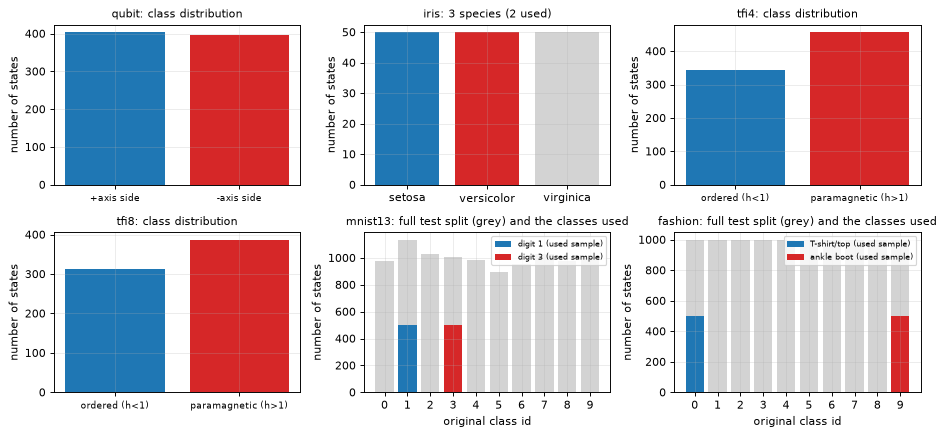

In [12]:
# ---------------- distribution of the real classes ----------------
fig, axs = plt.subplots(2, 3, figsize=(11, 5.2))
COL = ["tab:blue", "tab:red"]
for ax, (k, d) in zip(axs.ravel(), DS.items()):
    if k in ("mnist13", "fashion"):
        allc = CLASS_COUNTS_ALL[k]; used = d["orig_ids"]
        ax.bar(range(10), allc, color=["lightgray"] * 10)
        for ci, c in enumerate(used):
            ax.bar(c, np.bincount(d["y"])[ci], color=COL[ci], label=f"{d['classes'][ci]} (used sample)")
        ax.set_xlabel("original class id"); ax.set_xticks(range(10))
        ax.set_title(f"{k}: full test split (grey) and the classes used", fontsize=9)
    elif k == "iris":
        ax.bar([0, 1, 2], [50, 50, 50], color="lightgray"); ax.bar([0, 1], np.bincount(d["y"]), color=COL, label="used")
        ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["setosa", "versicolor", "virginica"]); ax.set_title("iris: 3 species (2 used)", fontsize=9)
    else:
        cnt = np.bincount(d["y"]); ax.bar(range(2), cnt, color=COL); ax.set_xticks(range(2)); ax.set_xticklabels(d["classes"], fontsize=8)
        ax.set_title(f"{k}: class distribution", fontsize=9)
    ax.set_ylabel("number of states")
    if k in ("mnist13", "fashion"): ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

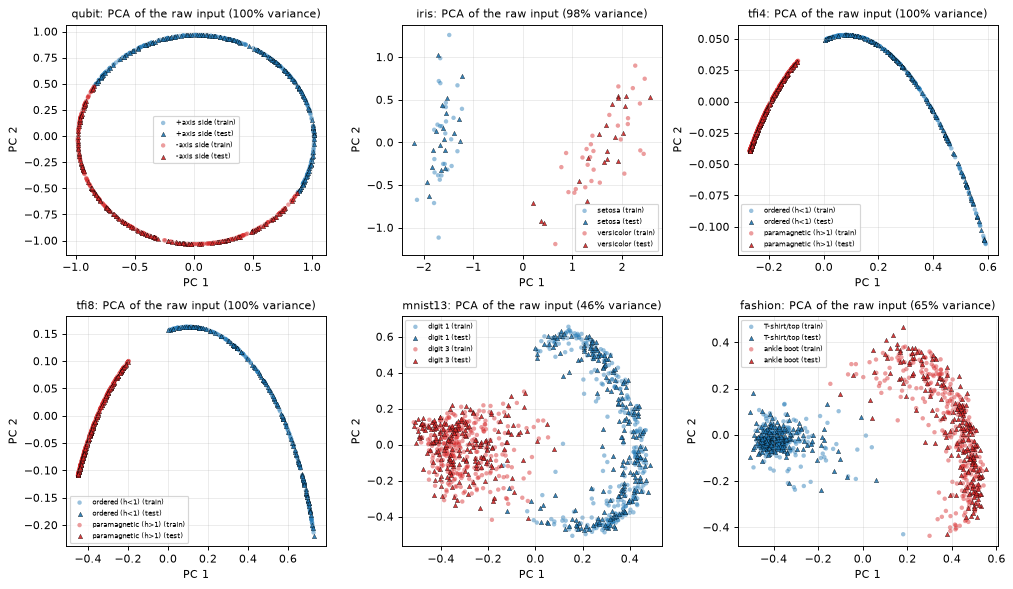

In [13]:
# ---------------- 2-D scatter of the real observations coloured by ground-truth label (PCA fitted on the training split) ----------------
def pca2(d):
    p = PCA(2, random_state=SEED).fit(d["raw"][d["tr"]]); return p, p.transform(d["raw"])

fig, axs = plt.subplots(2, 3, figsize=(12, 7))
PC2 = {}
for ax, (k, d) in zip(axs.ravel(), DS.items()):
    p, Z2 = pca2(d); PC2[k] = (p, Z2)
    for ci in (0, 1):
        for idx, mk, al in ((d["tr"], "o", 0.45), (d["te"], "^", 0.9)):
            sel = idx[d["y"][idx] == ci]
            ax.scatter(Z2[sel, 0], Z2[sel, 1], s=14, marker=mk, c=COL[ci], alpha=al, edgecolors="none" if mk == "o" else "k", linewidths=0.3,
                       label=f"{d['classes'][ci]} ({'train' if mk == 'o' else 'test'})")
    ax.set_title(f"{k}: PCA of the raw input ({p.explained_variance_ratio_.sum():.0%} variance)", fontsize=9)
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=6, loc="best")
plt.tight_layout(); plt.show()

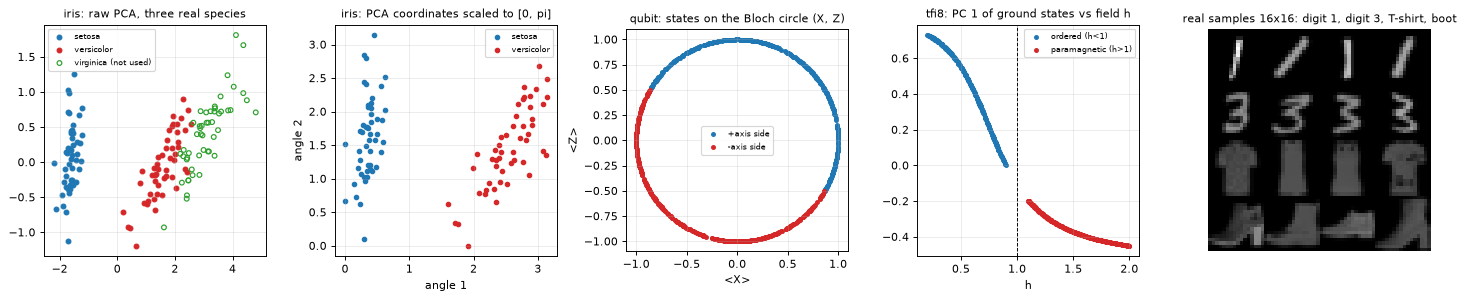

In [14]:
# ---------------- iris angles in [0, pi]; Bloch plane; Ising phases; sample images ----------------
fig, axs = plt.subplots(1, 5, figsize=(17, 3.6))
# (a) iris, three species, raw PCA fitted on the training split of the two used species
d = DS["iris"]; p = PCA(2, random_state=SEED).fit(d["raw"][d["tr"]])
Zall = p.transform(iris.data); sp = ["tab:blue", "tab:red", "tab:green"]
for c in range(3):
    m_ = iris.target == c
    axs[0].scatter(Zall[m_, 0], Zall[m_, 1], s=16, facecolors=sp[c] if c < 2 else "none", edgecolors=sp[c], label=iris.target_names[c] + ("" if c < 2 else " (not used)"))
axs[0].set_title("iris: raw PCA, three real species", fontsize=9); axs[0].legend(fontsize=7)
# (b) the same two coordinates scaled to [0, pi] (the angles an angle-encoding circuit would receive); scaler fitted on the training split
scp = MinMaxScaler((0, np.pi)).fit(PC2["iris"][1][d["tr"]]); A2 = np.clip(scp.transform(PC2["iris"][1]), 0, np.pi)
for ci in (0, 1):
    axs[1].scatter(A2[d["y"] == ci, 0], A2[d["y"] == ci, 1], s=14, c=COL[ci], label=d["classes"][ci])
axs[1].set_title("iris: PCA coordinates scaled to [0, pi]", fontsize=9); axs[1].set_xlabel("angle 1"); axs[1].set_ylabel("angle 2"); axs[1].legend(fontsize=7)
# (c) qubit: Bloch X-Z plane
d = DS["qubit"]
for ci in (0, 1): axs[2].scatter(d["raw"][d["y"] == ci, 0], d["raw"][d["y"] == ci, 1], s=10, c=COL[ci], label=d["classes"][ci])
axs[2].set_aspect("equal"); axs[2].set_title("qubit: states on the Bloch circle (X, Z)", fontsize=9); axs[2].set_xlabel("<X>"); axs[2].set_ylabel("<Z>"); axs[2].legend(fontsize=7)
# (d) Ising ground states: first principal component against the transverse field h
d = DS["tfi8"]; z1 = PC2["tfi8"][1][:, 0]
for ci in (0, 1): axs[3].scatter(d["h"][d["y"] == ci], z1[d["y"] == ci], s=10, c=COL[ci], label=d["classes"][ci])
axs[3].axvline(1, color="k", lw=0.8, ls="--"); axs[3].set_title("tfi8: PC 1 of ground states vs field h", fontsize=9); axs[3].set_xlabel("h"); axs[3].legend(fontsize=7)
# (e) sample images
d1, d2 = DS["mnist13"], DS["fashion"]
tile = np.concatenate([np.concatenate([DS[k]["states"][np.where(DS[k]["y"] == c)[0][j]].real.reshape(16, 16) for j in range(4)], 1) for k in ("mnist13", "fashion") for c in (0, 1)], 0)
axs[4].imshow(tile, cmap="gray"); axs[4].axis("off"); axs[4].set_title("real samples 16x16: digit 1, digit 3, T-shirt, boot", fontsize=9)
plt.tight_layout(); plt.show()

## 3. The six quantum classifiers and a classical baseline

**The model.** After the input state is prepared, `N_LAYERS` layers of `RY(theta) RZ(phi)` on every qubit followed by a ring of
CNOT gates `q -> q+1 (mod n)` are applied, then one more `RY` on every qubit; qubit 0 is measured in the computational
basis (`M_0 = |0><0|`). The prediction is label 0 if `<Z_0> > 0`. This is a standard hardware-efficient classifier of the family
the paper verifies (the paper's circuits come from MindSpore Quantum / TensorFlow Quantum and are not reproduced in the text).
For 8 qubits and 2 layers there are 40 trainable angles; 1 qubit has 5, 4 qubits have 20.

**Training.** Mean-squared error between `<Z_0>` and the target `+1` (label 0) / `-1` (label 1), Adam, mini-batches, back-propagation through
PennyLane's state-vector simulator (`default.qubit`, `diff_method="backprop"`). The training input states are only the
training split; the held-out split is used for verification. All verification below is done with the *exact* adjoint operator
`E^dagger(Z_0)` of the trained circuit, not with samples, so no shot noise enters any verdict.

**Classical baselines on identical inputs.** Logistic regression (linear), an RBF-SVC and a random forest, trained on exactly the same
real state vectors (the amplitudes the quantum model receives).

In [15]:
def init_params(n, r):                                    # CHOICE: small random angles
    return r.normal(0, 0.3, (N_LAYERS, n, 2)), r.normal(0, 0.3, n)

def build_ops(W, Wf, n):
    """Trainable circuit as an operation list: N_LAYERS x [RY, RZ on every qubit, CNOT ring], then RY on every qubit."""
    ops = []
    for l in range(W.shape[0]):
        for q in range(n):
            ops += [("RY", q, W[l, q, 0]), ("RZ", q, W[l, q, 1])]
        if n > 1: ops += [("CNOT", q, (q + 1) % n) for q in range(n)]
    ops += [("RY", q, Wf[q]) for q in range(n)]
    return ops

_f_cache = {}
def get_f(n):
    if n not in _f_cache:
        dev = qml.device("default.qubit", wires=n)
        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def f(W, Wf, psi):
            qml.StatePrep(psi, wires=range(n)); pl_apply(build_ops(W, Wf, n)); return qml.expval(qml.PauliZ(0))
        _f_cache[n] = f
    return _f_cache[n]

def train_qnn(n, X, y, steps, r, init=None, lr=LR):
    f = get_f(n); W, Wf = init if init is not None else init_params(n, r)
    W = pnp.array(W, requires_grad=True); Wf = pnp.array(Wf, requires_grad=True)
    tgt = pnp.array(1.0 - 2.0 * y); opt = qml.AdamOptimizer(lr); losses = []
    for s in range(steps):
        b = r.choice(len(X), size=min(BATCH, len(X)), replace=False)
        (W, Wf), c = opt.step_and_cost(lambda W_, Wf_: pnp.mean((f(W_, Wf_, X[b]) - tgt[b]) ** 2), W, Wf)
        losses.append(float(c))
    return np.array(W), np.array(Wf), losses

def as_float_ops(ops): return [(o[0], int(o[1]), float(o[2])) if o[0] != "CNOT" else (o[0], int(o[1]), int(o[2])) for o in ops]

MODELS = {k: [] for k in DS}
for name, d in DS.items():
    n = d["n"]; Xtr, ytr = d["states"][d["tr"]], d["y"][d["tr"]]
    for s in range(N_SEEDS):
        r = np.random.default_rng(SEED + 100 * s + 1); t0 = time.time()
        W, Wf, losses = train_qnn(n, Xtr, ytr, STEPS[name], r)
        ops0 = as_float_ops(build_ops(W, Wf, n)); O0 = observable_Z(ops0, 0, n)
        MODELS[name].append(dict(W=W, Wf=Wf, ops=ops0, losses=losses, time=time.time() - t0,
                                 acc_tr=float((margins(O0, Xtr, ytr) > 0).mean()),
                                 acc_te=float((margins(O0, d["states"][d["te"]], d["y"][d["te"]]) > 0).mean())))
    m0 = MODELS[name][0]
    print(f"{name:8s} qubits={n} params={W.size + Wf.size:3d}  steps={STEPS[name]:3d}  train acc {m0['acc_tr']:.3f}  test acc {m0['acc_te']:.3f}  ({m0['time']:.0f} s)")

qubit    qubits=1 params=  5  steps=200  train acc 0.990  test acc 0.988  (4 s)


iris     qubits=4 params= 20  steps=300  train acc 1.000  test acc 1.000  (30 s)


tfi4     qubits=4 params= 20  steps=300  train acc 0.887  test acc 0.903  (32 s)


tfi8     qubits=8 params= 40  steps=300  train acc 0.914  test acc 0.896  (106 s)


mnist13  qubits=8 params= 40  steps=300  train acc 0.982  test acc 0.975  (93 s)


fashion  qubits=8 params= 40  steps=300  train acc 0.993  test acc 0.988  (109 s)


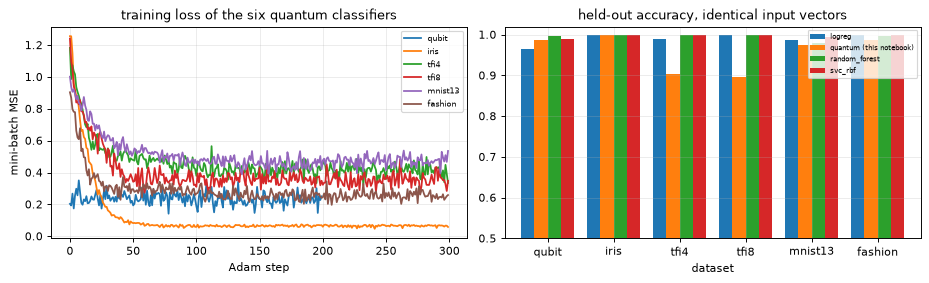

model,logreg,quantum (this notebook),random_forest,svc_rbf
dataset,,,,
qubit,0.966,0.988,0.997,0.991
iris,1.000,1.000,1.000,1.000
tfi4,0.991,0.903,1.000,1.000
tfi8,1.000,0.896,1.000,1.000
mnist13,0.988,0.975,0.980,0.995
fashion,1.000,0.988,0.998,1.000


In [16]:
# training curves + classical baselines on identical inputs
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name in DS:
    ax[0].plot(MODELS[name][0]["losses"], label=name)
ax[0].set_xlabel("Adam step"); ax[0].set_ylabel("mini-batch MSE"); ax[0].set_title("training loss of the six quantum classifiers"); ax[0].legend(fontsize=7)

base_rows = []
CLF = {}
for name, d in DS.items():
    assert np.abs(d["states"].imag).max() < 1e-12            # all inputs are real vectors, so classical models see the same numbers
    Xr_, y_ = d["states"].real, d["y"]
    for lbl, clf in [("logreg", LogisticRegression(max_iter=2000, random_state=SEED)), ("svc_rbf", SVC(kernel="rbf", C=1.0, random_state=SEED)),
                     ("random_forest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2))]:
        clf.fit(Xr_[d["tr"]], y_[d["tr"]]); CLF[(name, lbl)] = clf
        base_rows.append(dict(dataset=name, model=lbl, test_acc=clf.score(Xr_[d["te"]], y_[d["te"]])))
    base_rows.append(dict(dataset=name, model="quantum (this notebook)", test_acc=MODELS[name][0]["acc_te"]))
BASE = pd.DataFrame(base_rows).pivot(index="dataset", columns="model", values="test_acc").loc[list(DS)]
BASE.plot.bar(ax=ax[1], ylim=(0.5, 1.02), rot=0, width=0.8); ax[1].set_title("held-out accuracy, identical input vectors"); ax[1].legend(fontsize=6)
plt.tight_layout(); plt.show()
display(BASE.round(3))

## Quantum Circuit Architecture

The paper verifies three kinds of circuit: the noiseless model `c0`, the model with *random* noise `c1` (random channels at random
places) and the model with *specific* noise `c2` (`c1` plus a chosen channel on every qubit). We build those variants here and
draw the circuits that are actually executed: every drawing below is the PennyLane `qml.draw_mpl` of the very `QNode` that runs on
the density-matrix simulator `default.mixed`, built from the same operation list that the verification engine contracts. Channels
appear as boxes (`BitFlip`, `PhaseFlip`, `DepolarizingChannel`). Measurement is `<Z>` on qubit 0.

Assumptions where the paper omits details (also in the table at the top): the ansatz itself, the number of layers, the places and
probabilities of the random noise (`p ~ U(0, 0.02)`), the order of the three channels in "mixed" noise, and the input encoding.
Five distinct architectures are drawn: 1 qubit, 4 qubits with angle encoding (iris), 4 qubits with a state input (tfi4), 8 qubits
with a state input (tfi8 / fashion / mnist share it, only the weights differ) and a 10-qubit QAOA ring used for the global part.

In [17]:
# ---------------- noisy variants c0 / c1 / c2 ----------------
def add_random_noise(ops, n, r, pmax=P_RAND_MAX):
    """c1: one random channel (BF/PF/DC) per qubit at a random position of the circuit, probability U(0, pmax)."""
    ops = list(ops); ins = []
    for q in range(n):
        pos = int(r.integers(0, len(ops) + 1)); kind = str(r.choice(["BF", "PF", "DC"])); ins.append((pos, (kind, q, float(r.uniform(0, pmax)))))
    for pos, op in sorted(ins, key=lambda t: -t[0]): ops.insert(pos, op)
    return ops

KIND = {"bit-flip": ["BF"], "phase-flip": ["PF"], "depolarizing": ["DC"], "mixed": ["BF", "PF", "DC"]}
def add_specific_noise(ops, n, noise, p):
    """c2: after c1, the chosen channel with probability p on every qubit (for 'mixed': BF, PF, DC one after the other)."""
    ops = list(ops)
    for q in range(n):
        for k in KIND[noise]: ops.append((k, q, float(p)))
    return ops

T1_SETTINGS = {"qubit": [("depolarizing", 0.001), ("depolarizing", 0.005)], "iris": [("mixed", 0.01), ("mixed", 0.05)],
               "tfi4": [("mixed", 0.01), ("mixed", 0.05)], "tfi8": [("bit-flip", 0.01), ("bit-flip", 0.05)],
               "fashion": [("bit-flip", 0.01), ("bit-flip", 0.05)], "mnist13": [("phase-flip", 0.001), ("phase-flip", 0.01)]}
VAR = {}
for name, d in DS.items():
    n = d["n"]; r = np.random.default_rng(SEED + 7)
    c0 = MODELS[name][0]["ops"]; c1 = add_random_noise(c0, n, r)
    VAR[name] = dict(c0=c0, c1=c1, c2=[(nz, p, add_specific_noise(c1, n, nz, p)) for nz, p in T1_SETTINGS[name]])
    print(f"{name:8s} c0: {len(c0)} ops | c1: +{len(c1) - len(c0)} random channels: " +
          ", ".join(f"{o[0]}@q{o[1]}(p={o[2]:.4f})" for o in c1 if o[0] in ('BF', 'PF', 'DC'))[:150])

def qaoa_ops(n, gammas=(0.4, 0.7), betas=(0.3, 0.2)):
    """QAOA-style ring (MaxCut cost layer exp(-i g sum Z_i Z_i+1) as CNOT-RZ-CNOT, RX mixer as RZ-RY-RZ). CHOICE: fixed angles, not trained."""
    ops = [("RY", q, np.pi / 2) for q in range(n)]
    edges = [(q, (q + 1) % n) for q in range(0, n, 2)] + [(q, (q + 1) % n) for q in range(1, n, 2)]    # even edges, then odd edges (they commute)
    for g, b in zip(gammas, betas):
        for a, c in edges: ops += [("CNOT", a, c), ("RZ", c, 2 * g), ("CNOT", a, c)]
        for q in range(n): ops += [("RZ", q, np.pi / 2), ("RY", q, 2 * b), ("RZ", q, -np.pi / 2)]
    return ops
th_ = 0.7                                                   # sanity check of the RX decomposition
assert np.allclose(RZ(-np.pi / 2) @ RY(th_) @ RZ(np.pi / 2), np.cos(th_ / 2) * I2 - 1j * np.sin(th_ / 2) * X)
QAOA10_C1 = add_random_noise(qaoa_ops(10), 10, np.random.default_rng(SEED + 8))

qubit    c0: 5 ops | c1: +1 random channels: PF@q0(p=0.0119)
iris     c0: 28 ops | c1: +4 random channels: PF@q1(p=0.0125), PF@q0(p=0.0119), DC@q3(p=0.0199), PF@q2(p=0.0003)
tfi4     c0: 28 ops | c1: +4 random channels: PF@q1(p=0.0125), PF@q0(p=0.0119), DC@q3(p=0.0199), PF@q2(p=0.0003)
tfi8     c0: 56 ops | c1: +8 random channels: PF@q4(p=0.0022), PF@q6(p=0.0144), PF@q1(p=0.0125), PF@q0(p=0.0119), DC@q7(p=0.0114), DC@q5(p=0.0125), DC@q3(p=0.0199), PF@q2(p=0.0003)
mnist13  c0: 56 ops | c1: +8 random channels: PF@q4(p=0.0022), PF@q6(p=0.0144), PF@q1(p=0.0125), PF@q0(p=0.0119), DC@q7(p=0.0114), DC@q5(p=0.0125), DC@q3(p=0.0199), PF@q2(p=0.0003)
fashion  c0: 56 ops | c1: +8 random channels: PF@q4(p=0.0022), PF@q6(p=0.0144), PF@q1(p=0.0125), PF@q0(p=0.0119), DC@q7(p=0.0114), DC@q5(p=0.0125), DC@q3(p=0.0199), PF@q2(p=0.0003)


qubit (c2 depolarizing 0.005)      qubits= 1  depth(PennyLane)=  8  depth(op list, no encoding)=  7  gates+channels=  7 (channels  2)  trainable angles=5


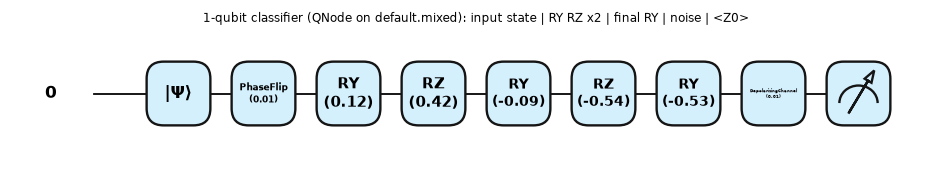

iris, angle-encoded (c2 mixed 0.05) qubits= 4  depth(PennyLane)= 18  depth(op list, no encoding)= 17  gates+channels= 44 (channels 16)  trainable angles=20


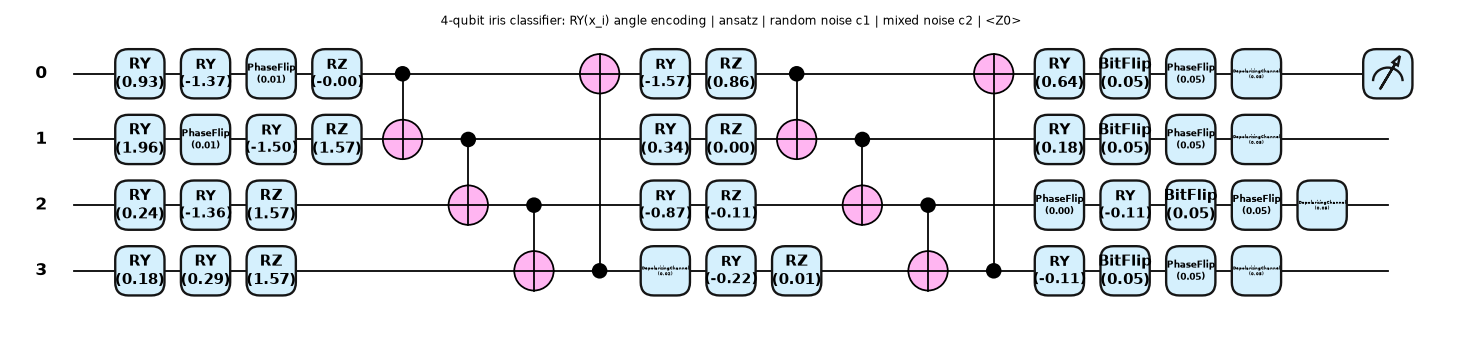

tfi4, state input (c2 mixed 0.05)  qubits= 4  depth(PennyLane)= 18  depth(op list, no encoding)= 17  gates+channels= 44 (channels 16)  trainable angles=20


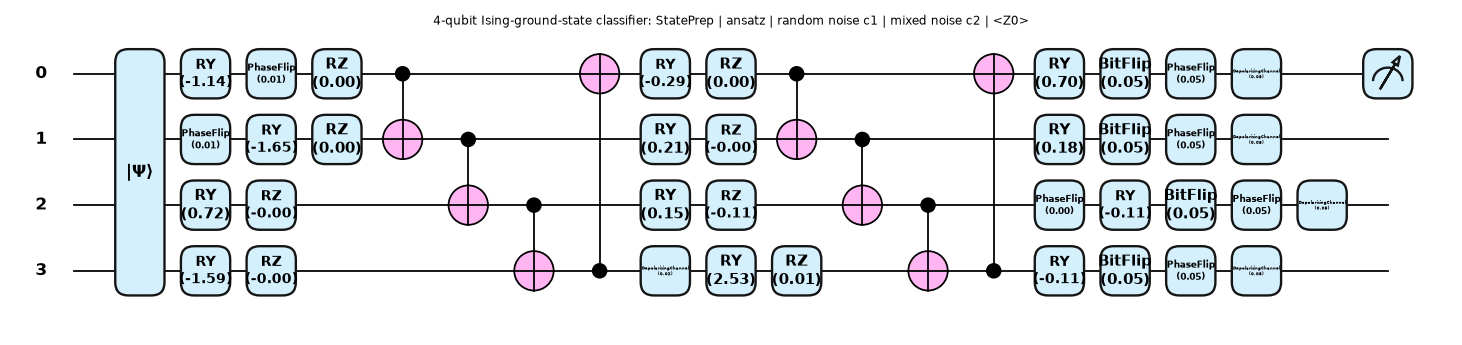

In [18]:
# ---------------- depth, qubits, parameters; engine == simulator on the exact circuits that are drawn ----------------
def ops_depth(ops, n):
    lvl = [0] * n
    for o in ops:
        qs = (o[1], o[2]) if o[0] == "CNOT" else (o[1],)
        h = max(lvl[q] for q in qs) + 1
        for q in qs: lvl[q] = h
    return max(lvl)

def describe(label, n, ops, qn, arg, trainable):
    sp = qml.specs(qn)(arg); res = sp["resources"]
    n_ch = sum(o[0] in ("BF", "PF", "DC") for o in ops)
    print(f"{label:34s} qubits={n:2d}  depth(PennyLane)={res.depth:3d}  depth(op list, no encoding)={ops_depth(ops, n):3d}  gates+channels={len(ops):3d} "
          f"(channels {n_ch:2d})  trainable angles={trainable}")

def check_equiv(n, ops, states, qn, k=3):
    O = observable_Z(ops, 0, n)
    for psi in states[:k]:
        assert abs(qn(psi) - np.real(psi.conj() @ O @ psi)) < 1e-9, "engine != default.mixed"

def show(qn, arg, title, width=None):
    fig, ax = qml.draw_mpl(qn, decimals=2, style="pennylane")(arg)
    fig.suptitle(title, fontsize=10)
    if width: fig.set_size_inches(width, fig.get_size_inches()[1] * width / fig.get_size_inches()[0])
    plt.show()

CIRCUIT_CHECKS = []
# 1) one qubit, c2 depolarizing 0.005
nz, p, ops = VAR["qubit"]["c2"][1]; qn = mixed_qnode(1, ops); d = DS["qubit"]
check_equiv(1, ops, d["states"], qn); describe("qubit (c2 depolarizing 0.005)", 1, ops, qn, d["states"][0], N_LAYERS * 2 + 1)
show(qn, d["states"][0], "1-qubit classifier (QNode on default.mixed): input state | RY RZ x2 | final RY | noise | <Z0>")

# 2) iris: angle encoding RY(x_q), c2 mixed 0.05; equivalence with the StatePrep input used for training
nz, p, ops = VAR["iris"]["c2"][1]; qn_ang = mixed_qnode(4, ops, encode="angles"); qn_sp = mixed_qnode(4, ops); d = DS["iris"]
for i in range(5):
    assert abs(qn_ang(d["angles"][i]) - qn_sp(d["states"][i])) < 1e-10, "angle encoding != product state"
check_equiv(4, ops, d["states"], qn_sp); describe("iris, angle-encoded (c2 mixed 0.05)", 4, ops, qn_ang, d["angles"][0], N_LAYERS * 8 + 4)
show(qn_ang, d["angles"][0], "4-qubit iris classifier: RY(x_i) angle encoding | ansatz | random noise c1 | mixed noise c2 | <Z0>", width=17)

# 3) tfi4, state input, c2 mixed 0.05
nz, p, ops = VAR["tfi4"]["c2"][1]; qn = mixed_qnode(4, ops); d = DS["tfi4"]
check_equiv(4, ops, d["states"], qn); describe("tfi4, state input (c2 mixed 0.05)", 4, ops, qn, d["states"][0], N_LAYERS * 8 + 4)
show(qn, d["states"][0], "4-qubit Ising-ground-state classifier: StatePrep | ansatz | random noise c1 | mixed noise c2 | <Z0>", width=17)

tfi8, state input (c2 bit-flip 0.05) qubits= 8  depth(PennyLane)= 24  depth(op list, no encoding)= 23  gates+channels= 72 (channels 16)  trainable angles=40


fashion, state input (c2 bit-flip 0.05) qubits= 8  depth(PennyLane)= 24  depth(op list, no encoding)= 23  gates+channels= 72 (channels 16)  trainable angles=40


mnist13, state input (c2 phase-flip 0.01) qubits= 8  depth(PennyLane)= 24  depth(op list, no encoding)= 23  gates+channels= 72 (channels 16)  trainable angles=40


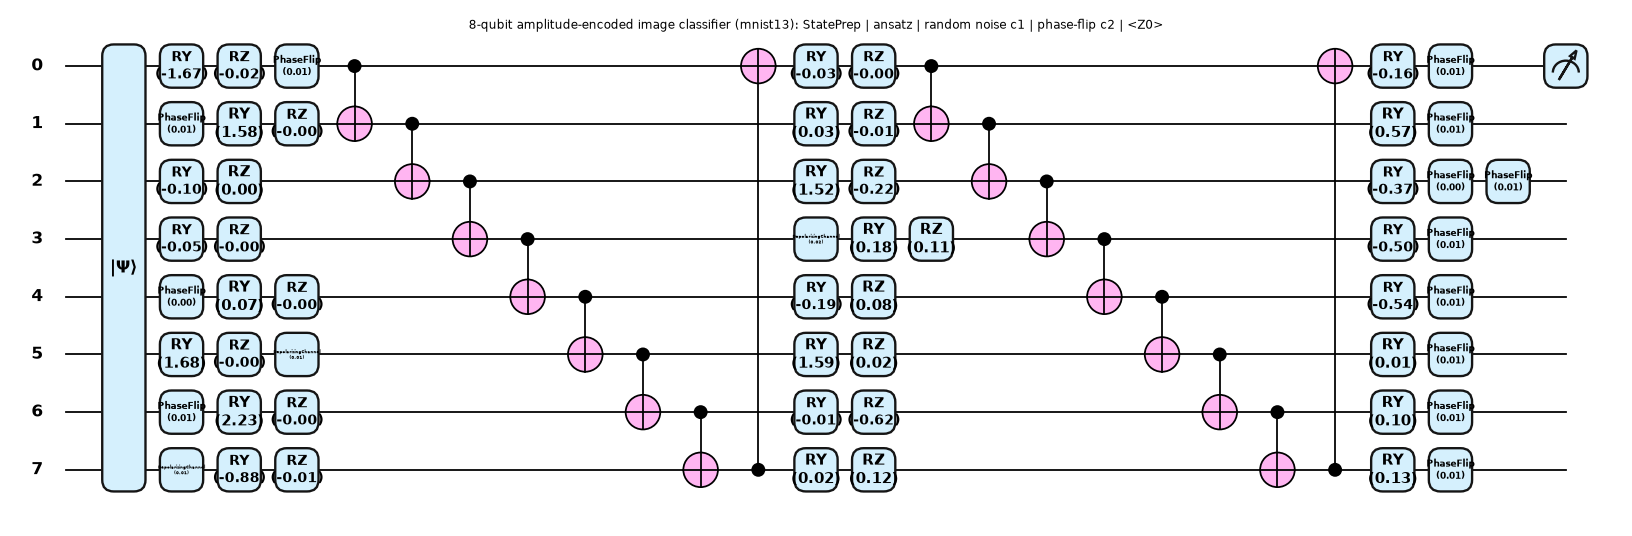

qaoa10 (c1 random noise)           qubits=10  depth(PennyLane)= 22  depth(op list, no encoding)= 21  gates+channels=140 (channels 10)  trainable angles=0


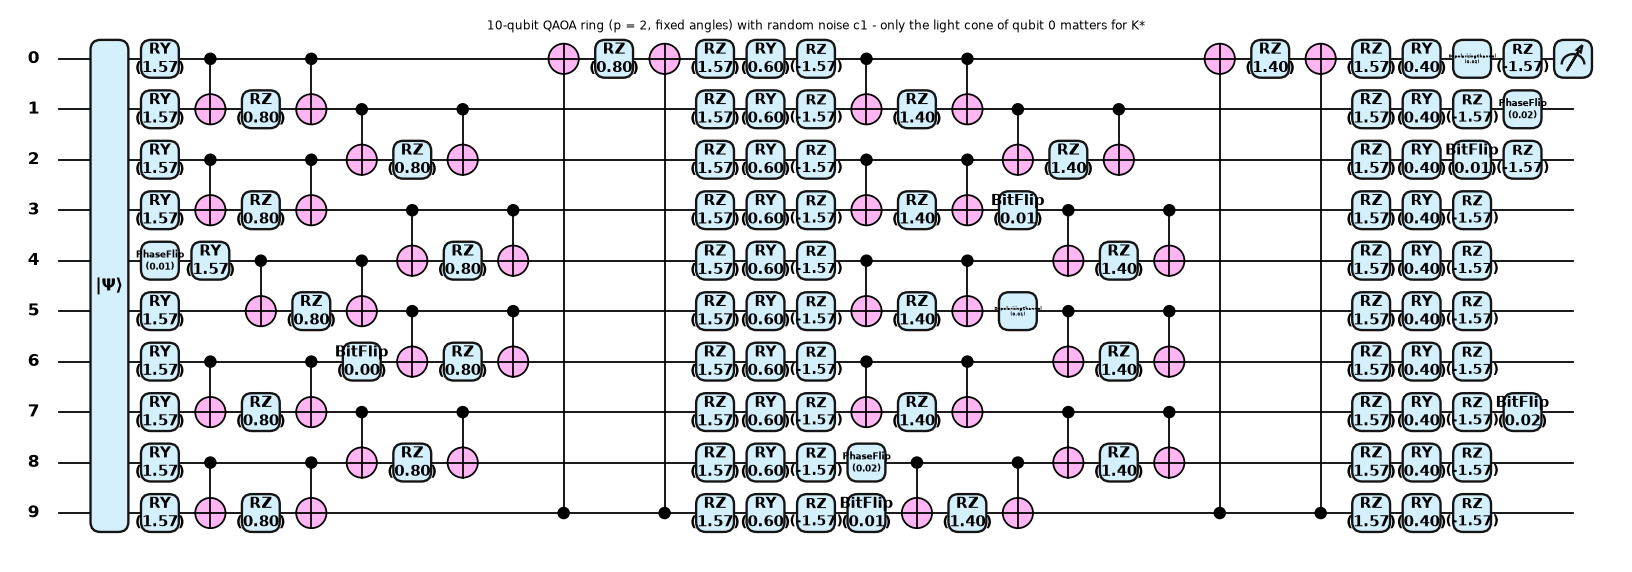

All drawn circuits reproduce the engine's <Z0> on real data states to < 1e-9 (assertions above).


In [19]:
# 4) 8 qubits (tfi8 / fashion / mnist13 share the architecture): draw mnist13 with c2 phase-flip 0.01 and check all three 8-qubit models
for name in ("tfi8", "fashion", "mnist13"):
    nz, p, ops = VAR[name]["c2"][1]; qn = mixed_qnode(8, ops); d = DS[name]
    check_equiv(8, ops, d["states"], qn, k=2)
    describe(f"{name}, state input (c2 {nz} {p})", 8, ops, qn, d["states"][0], N_LAYERS * 16 + 8)
    if name == "mnist13":
        show(qn, d["states"][0], "8-qubit amplitude-encoded image classifier (mnist13): StatePrep | ansatz | random noise c1 | phase-flip c2 | <Z0>", width=19)

# 5) 10-qubit QAOA ring used for the global part (fixed angles, c1 random noise)
qn = mixed_qnode(10, QAOA10_C1); s0 = np.zeros(2 ** 10, complex); s0[0] = 1
describe("qaoa10 (c1 random noise)", 10, QAOA10_C1, qn, s0, 0)
show(qn, s0, "10-qubit QAOA ring (p = 2, fixed angles) with random noise c1 - only the light cone of qubit 0 matters for K*", width=19)
print("All drawn circuits reproduce the engine's <Z0> on real data states to < 1e-9 (assertions above).")

## 4. Local robustness: the paper's Table 1, rebuilt

For every model the held-out states of the data set (first `N_VERIFY` of them) are verified at the paper's epsilon of Table 1, on `c0`, `c1`
and the two `c2` settings of that row. Following the paper's description:

* **Rough Verif**: compute `E^dagger(Z_0)`, then declare robust only the states that pass the sufficient condition.
* **Accurate Verif**: the rough test filters; for every other *correctly classified* state the exact SDP (dual) decides. A
  misclassified state is not robust (the state itself is in its own neighbourhood).
* **RA** is the percentage of robust states, **VT** the wall-clock time for the whole set including the operator construction.

An independent projected-gradient attack gives an empirical upper bound `RA_attack`, so we must see
`RA_rough <= RA_exact <= RA_attack`.

**Two readings of "Fbar <= eps".** The paper does not define `Fbar`. *Reading A* (used in the maths of section 1): the ball is `1 - F <= eps`, so
the trace distance may reach `sqrt(eps)`. *Reading B*: `Fbar` is the purified distance `sqrt(1 - F)`, so the ball is `1 - F <= eps^2` and the trace distance may reach `eps`. Both
are run on every row; they differ by orders of magnitude in the size of the ball. The "paper" columns are the paper's numbers.

In [20]:
def prepare_local(ops, name, nv=None):
    """Heisenberg operator O = E^dagger(Z_0) of a circuit and the margins of the first `nv` held-out states (the part shared by all epsilons)."""
    nv = nv or N_VERIFY
    d = DS[name]; n = d["n"]; idx = d["te"][:nv]; S = d["states"][idx]; y = d["y"][idx]
    t0 = time.perf_counter()
    O = observable_Z(ops, 0, n); w = np.linalg.eigvalsh(O); m = margins(O, S, y)
    return dict(name=name, n=n, idx=idx, S=S, y=y, O=O, w=w, m=m, t_O=time.perf_counter() - t0)

def verify_prepared(P, eps, attack=True, keep=False):
    """Rough and accurate verification at one epsilon (eps is the infidelity 1-F of the ball), VT includes the operator construction."""
    O, w, m, S, y = P["O"], P["w"], P["m"], P["S"], P["y"]
    t0 = time.perf_counter(); thr = (w[-1] - w[0]) * np.sqrt(eps); rough = m > thr
    t_rough = P["t_O"] + time.perf_counter() - t0
    hard = np.where((~rough) & (m > 0))[0]                       # correctly classified but not certified by the rough test
    t1 = time.perf_counter(); ex = {}; dual = {}; exact = rough.copy()
    for i in hard:
        s = 1 if y[i] == 0 else -1
        if s not in ex: ex[s] = ExactLocal(O, s)
        dual[i] = ex[s].dual_min(S[i], eps); exact[i] = dual[i] > 0
    t_exact = t_rough + time.perf_counter() - t1
    broken = np.zeros(len(S), bool)
    if attack:
        ra = np.random.default_rng(SEED)
        for i in hard:
            s = 1 if y[i] == 0 else -1
            broken[i] = pgd_attack(O, S[i], s, eps, rng=ra)[0] <= 0
    att_ok = (m > 0) & ~broken
    out = dict(acc=100 * float((m > 0).mean()), ra_rough=100 * float(rough.mean()), vt_rough=t_rough, ra_exact=100 * float(exact.mean()),
               vt_exact=t_exact, ra_attack=100 * float(att_ok.mean()), n_hard=len(hard), K=(w[-1] - w[0]) / 2, n=len(S))
    if keep: out.update(O=O, m=m, rough=rough, exact=exact, dual=dual, hard=hard, idx=P["idx"], thr=thr)
    return out

def verify_local(ops, name, eps, nv=None, attack=True, keep=False):
    return verify_prepared(prepare_local(ops, name, nv), eps, attack, keep)

# The paper writes the neighbourhood as Fbar(rho, sigma) <= eps without defining Fbar. Two readings are run side by side:
#   A "fidelity ball":          1 - F <= eps          (F = squared fidelity)       -> infidelity eps_F = eps
#   B "purified-distance ball": sqrt(1 - F) <= eps    (Bures/sine distance)        -> infidelity eps_F = eps**2
def eps_A(e): return e
def eps_B(e): return e ** 2

PAPER_T1 = [  # model, qubits, eps, circuit, noise, RA rough, VT rough, RA accurate, VT accurate   (Table 1 of the paper)
 ("qubit",1,0.001,"c0","noiseless",88.12,0.0038,90,2.4226), ("qubit",1,0.001,"c1","random",88.12,0.0039,90,2.4623),
 ("qubit",1,0.001,"c2","depolarizing_0.001",88.00,0.0038,90,2.4873), ("qubit",1,0.001,"c2","depolarizing_0.005",87.62,0.0053,90,2.7140),
 ("iris",4,0.005,"c0","noiseless",98.75,0.0013,100,0.4924), ("iris",4,0.005,"c1","random",97.50,0.0009,100,0.8876),
 ("iris",4,0.005,"c2","mixed_0.01",97.50,0.0019,100,0.8808), ("iris",4,0.005,"c2","mixed_0.05",96.25,0.0021,100,3.1675),
 ("tfi4",4,0.005,"c0","noiseless",86.41,0.0039,100,6.5220), ("tfi4",4,0.005,"c1","random",85.94,0.0038,100,6.6438),
 ("tfi4",4,0.005,"c2","mixed_0.01",85.78,0.0061,100,6.7117), ("tfi4",4,0.005,"c2","mixed_0.05",85.16,0.0063,100,7.0374),
 ("tfi8",8,0.005,"c0","noiseless",98.44,0.0372,100,2.3004), ("tfi8",8,0.005,"c1","random",96.56,0.1061,100,3.9492),
 ("tfi8",8,0.005,"c2","bit-flip_0.01",96.56,37.0965,100,42.1246), ("tfi8",8,0.005,"c2","bit-flip_0.05",95.94,32.7195,100,38.8139),
 ("fashion",8,0.001,"c0","noiseless",90.60,0.0420,97.40,25.3777), ("fashion",8,0.001,"c1","random",90.30,0.0934,97.30,27.4964),
 ("fashion",8,0.001,"c2","bit-flip_0.01",89.90,15.6579,97.20,42.1063), ("fashion",8,0.001,"c2","bit-flip_0.05",87.60,14.0342,96.70,48.5805),
 ("mnist13",8,0.003,"c0","noiseless",93.80,0.0543,96.00,18.5063), ("mnist13",8,0.003,"c1","random",92.60,0.0785,95.70,23.2905),
 ("mnist13",8,0.003,"c2","phase-flip_0.001",92.60,12.9728,95.70,36.2348), ("mnist13",8,0.003,"c2","phase-flip_0.01",92.60,11.6704,95.70,33.7894)]
assert len(PAPER_T1) == 24

def variant_ops(name, circ, noise):
    v = VAR[name]
    if circ == "c0": return v["c0"]
    if circ == "c1": return v["c1"]
    return next(o for nz, p, o in v["c2"] if f"{nz}_{p}" == noise)

rows = []
for (name, nq, eps, circ, noise, pr, pvr, pa, pva) in PAPER_T1:
    assert abs(EPS[name] - eps) < 1e-12 and DS[name]["n"] == nq
    P = prepare_local(variant_ops(name, circ, noise), name)
    tA = verify_prepared(P, eps_A(eps)); tB = verify_prepared(P, eps_B(eps))
    rows.append(dict(model=name, qubits=nq, eps=eps, circuit=circ, noise=noise, acc=tA["acc"],
                     RA_rough=tA["ra_rough"], RA_exact=tA["ra_exact"], RA_attack=tA["ra_attack"],
                     RA_rough_B=tB["ra_rough"], RA_exact_B=tB["ra_exact"], RA_attack_B=tB["ra_attack"],
                     RA_rough_paper=pr, RA_exact_paper=pa,
                     VT_rough=tA["vt_rough"], VT_rough_paper=pvr, VT_exact=tA["vt_exact"], VT_exact_paper=pva,
                     K_star=tA["K"], n_hard=tA["n_hard"], n_hard_B=tB["n_hard"], n_states=tA["n"]))
    print(f"{name:8s} {circ} {noise:19s} acc {tA['acc']:6.2f} | A: RA rough/exact/attack {tA['ra_rough']:6.2f}/{tA['ra_exact']:6.2f}/{tA['ra_attack']:6.2f} "
          f"| B: {tB['ra_rough']:6.2f}/{tB['ra_exact']:6.2f}/{tB['ra_attack']:6.2f} | VT(A) {tA['vt_rough']:.3f}/{tA['vt_exact']:.3f} s", flush=True)
T1 = pd.DataFrame(rows)
for sfx in ("", "_B"):
    assert (T1["RA_rough" + sfx] <= T1["RA_exact" + sfx] + 1e-9).all(), "rough bound is not sound"
    assert (T1["RA_exact" + sfx] <= T1["RA_attack" + sfx] + 1e-9).all(), "exact RA above the attack's: the exact verifier would be wrong"
    assert (T1["RA_exact" + sfx] <= T1.acc + 1e-9).all()
print("\nsandwich verified in all 24 rows and both readings:  RA_rough <= RA_exact <= RA_attack  and  RA_exact <= accuracy")

qubit    c0 noiseless           acc  98.75 | A: RA rough/exact/attack  95.62/ 95.62/ 95.62 | B:  98.44/ 98.44/ 98.44 | VT(A) 0.001/0.125 s


qubit    c1 random              acc  97.81 | A: RA rough/exact/attack  95.00/ 95.00/ 95.00 | B:  97.81/ 97.81/ 97.81 | VT(A) 0.001/0.031 s


qubit    c2 depolarizing_0.001  acc  97.81 | A: RA rough/exact/attack  95.00/ 95.00/ 95.00 | B:  97.81/ 97.81/ 97.81 | VT(A) 0.001/0.041 s


qubit    c2 depolarizing_0.005  acc  97.81 | A: RA rough/exact/attack  95.00/ 95.00/ 95.00 | B:  97.81/ 97.81/ 97.81 | VT(A) 0.001/0.034 s


iris     c0 noiseless           acc 100.00 | A: RA rough/exact/attack 100.00/100.00/100.00 | B: 100.00/100.00/100.00 | VT(A) 0.003/0.003 s


...

mnist13  c0 noiseless           acc  97.50 | A: RA rough/exact/attack  91.00/ 91.00/ 91.00 | B:  97.50/ 97.50/ 97.50 | VT(A) 1.182/1.570 s


mnist13  c1 random              acc  98.00 | A: RA rough/exact/attack  91.00/ 91.25/ 91.25 | B:  97.50/ 97.50/ 97.50 | VT(A) 1.053/1.340 s


mnist13  c2 phase-flip_0.001    acc  98.00 | A: RA rough/exact/attack  91.00/ 91.25/ 91.25 | B:  97.50/ 97.50/ 97.50 | VT(A) 1.380/1.763 s


mnist13  c2 phase-flip_0.01     acc  98.00 | A: RA rough/exact/attack  91.00/ 91.25/ 91.25 | B:  97.50/ 97.50/ 97.50 | VT(A) 0.902/1.175 s



sandwich verified in all 24 rows and both readings:  RA_rough <= RA_exact <= RA_attack  and  RA_exact <= accuracy


Reading A (1 - F <= eps):


,model,circuit,noise,acc,RA_rough,RA_rough_paper,RA_exact,RA_exact_paper,RA_attack,VT_rough,VT_exact,VT_exact_paper,K_star
0,qubit,c0,noiseless,98.75,95.62,88.12,95.62,90.0,95.62,0.0009,0.125,2.4226,1.0000
1,qubit,c1,random,97.81,95.00,88.12,95.00,90.0,95.00,0.0011,0.031,2.4623,0.9947
2,qubit,c2,depolarizing_0.001,97.81,95.00,88.00,95.00,90.0,95.00,0.0011,0.041,2.4873,0.9934
3,qubit,c2,depolarizing_0.005,97.81,95.00,87.62,95.00,90.0,95.00,0.0014,0.034,2.7140,0.9881
4,iris,c0,noiseless,100.00,100.00,98.75,100.00,100.0,100.00,0.0035,0.003,0.4924,1.0000
5,iris,c1,random,100.00,100.00,97.50,100.00,100.0,100.00,0.0043,0.004,0.8876,0.9669
6,iris,c2,mixed_0.01,100.00,100.00,97.50,100.00,100.0,100.00,0.0052,0.005,0.8808,0.9349
7,iris,c2,mixed_0.05,100.00,100.00,96.25,100.00,100.0,100.00,0.0051,0.005,3.1675,0.8122
8,tfi4,c0,noiseless,90.31,85.00,86.41,85.00,100.0,85.00,0.0045,0.079,6.5220,1.0000
9,tfi4,c1,random,90.31,85.00,85.94,85.00,100.0,85.00,0.0053,0.587,6.6438,0.9674


Reading B (sqrt(1 - F) <= eps, i.e. infidelity eps^2):


,model,circuit,noise,acc,RA_rough_B,RA_rough_paper,RA_exact_B,RA_exact_paper,RA_attack_B,n_hard_B
0,qubit,c0,noiseless,98.75,98.44,88.12,98.44,90.0,98.44,1
1,qubit,c1,random,97.81,97.81,88.12,97.81,90.0,97.81,0
2,qubit,c2,depolarizing_0.001,97.81,97.81,88.00,97.81,90.0,97.81,0
3,qubit,c2,depolarizing_0.005,97.81,97.81,87.62,97.81,90.0,97.81,0
4,iris,c0,noiseless,100.00,100.00,98.75,100.00,100.0,100.00,0
5,iris,c1,random,100.00,100.00,97.50,100.00,100.0,100.00,0
6,iris,c2,mixed_0.01,100.00,100.00,97.50,100.00,100.0,100.00,0
7,iris,c2,mixed_0.05,100.00,100.00,96.25,100.00,100.0,100.00,0
8,tfi4,c0,noiseless,90.31,90.31,86.41,90.31,100.0,90.31,0
9,tfi4,c1,random,90.31,90.31,85.94,90.31,100.0,90.31,0


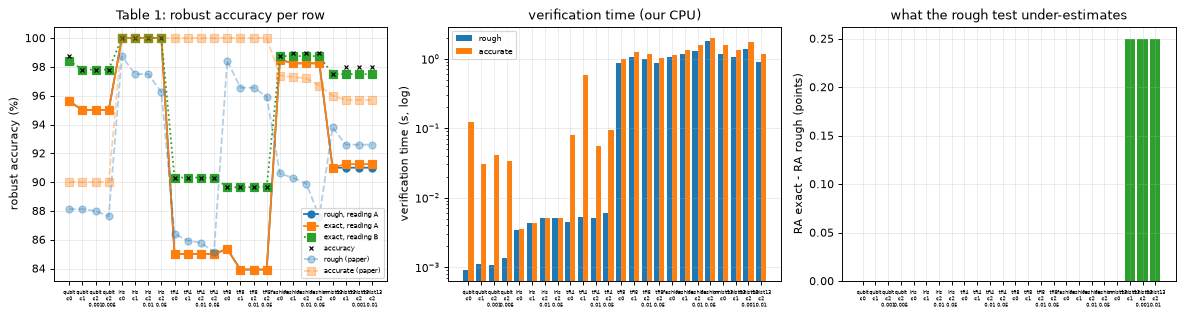

In [21]:
pd.set_option("display.width", 220)
print("Reading A (1 - F <= eps):")
show_cols = ["model", "circuit", "noise", "acc", "RA_rough", "RA_rough_paper", "RA_exact", "RA_exact_paper", "RA_attack", "VT_rough", "VT_exact", "VT_exact_paper", "K_star"]
display(T1[show_cols].round({"acc": 2, "RA_rough": 2, "RA_exact": 2, "RA_attack": 2, "VT_rough": 4, "VT_exact": 3, "K_star": 4}))
print("Reading B (sqrt(1 - F) <= eps, i.e. infidelity eps^2):")
display(T1[["model", "circuit", "noise", "acc", "RA_rough_B", "RA_rough_paper", "RA_exact_B", "RA_exact_paper", "RA_attack_B", "n_hard_B"]].round(2))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
lab = [f"{r.model}\n{r.circuit}" + ("" if r.circuit != "c2" else f"\n{r.noise.split('_')[1]}") for r in T1.itertuples()]
xs = np.arange(len(T1))
axs[0].plot(xs, T1.RA_rough, "o-", c="tab:blue", label="rough, reading A"); axs[0].plot(xs, T1.RA_exact, "s-", c="tab:orange", label="exact, reading A")
axs[0].plot(xs, T1.RA_exact_B, "s:", c="tab:green", label="exact, reading B"); axs[0].plot(xs, T1.acc, "x", c="k", ms=4, label="accuracy")
axs[0].plot(xs, T1.RA_rough_paper, "o--", c="tab:blue", alpha=0.35, label="rough (paper)"); axs[0].plot(xs, T1.RA_exact_paper, "s--", c="tab:orange", alpha=0.35, label="accurate (paper)")
axs[0].set_xticks(xs); axs[0].set_xticklabels(lab, fontsize=4.5); axs[0].set_ylabel("robust accuracy (%)"); axs[0].legend(fontsize=6); axs[0].set_title("Table 1: robust accuracy per row")
axs[1].bar(xs - 0.2, T1.VT_rough, 0.4, label="rough"); axs[1].bar(xs + 0.2, T1.VT_exact, 0.4, label="accurate"); axs[1].set_yscale("log")
axs[1].set_xticks(xs); axs[1].set_xticklabels(lab, fontsize=4.5); axs[1].set_ylabel("verification time (s, log)"); axs[1].legend(fontsize=7); axs[1].set_title("verification time (our CPU)")
gap = T1.RA_exact - T1.RA_rough
axs[2].bar(xs, gap, color="tab:green"); axs[2].set_xticks(xs); axs[2].set_xticklabels(lab, fontsize=4.5); axs[2].set_ylabel("RA exact - RA rough (points)"); axs[2].set_title("what the rough test under-estimates")
plt.tight_layout(); plt.show()

In [22]:
# ---------------- is the exact verifier exact?  primal (pure adversarial example) vs dual (SDP) vs attack, on every model's noisy c1 circuit ----------------
chk = []
for name in DS:
    eps = EPS[name]; t = verify_local(VAR[name]["c1"], name, eps, keep=True, attack=False)
    O, m, hard, idx = t["O"], t["m"], t["hard"], t["idx"]; S = DS[name]["states"][idx]; y = DS[name]["y"][idx]
    ex = {1: ExactLocal(O, 1), -1: ExactLocal(O, -1)}; gaps = []; miss = 0; false_adv = 0; found = 0
    ra = np.random.default_rng(SEED)
    for i in hard:
        s = 1 if y[i] == 0 else -1
        dv = t["dual"][i]; pv, phi = ex[s].primal_pure(S[i], eps); av, _ = pgd_attack(O, S[i], s, eps, rng=ra)
        gaps.append(abs(dv - pv))
        if dv <= 0:
            found += 1; miss += int(av > 0)                    # exact says "adversarial example exists" but PGD did not find one
            assert pv <= 1e-6, "exact dual says non-robust but no adversarial state found by the primal"
        else:
            false_adv += int(av <= 0 or pv <= 0)                # a "violation" here would contradict the dual certificate
    assert false_adv == 0, "an attack broke a state the exact verifier certified"
    chk.append(dict(model=name, hard_states=len(hard), non_robust=found, max_gap_primal_dual=max(gaps) if gaps else 0.0, PGD_missed=miss, attacks_on_certified=false_adv))
display(pd.DataFrame(chk).set_index("model"))
print("primal = dual to numerical precision, and no attack ever breaks a certified state: the verdicts are exact (sound and complete) for pure inputs.")

,hard_states,non_robust,max_gap_primal_dual,PGD_missed,attacks_on_certified
model,,,,,
qubit,9,9,2.414735e-14,0,0
iris,0,0,0.000000e+00,0,0
tfi4,17,17,3.053113e-14,0,0
tfi8,16,16,2.414735e-14,0,0
mnist13,28,27,8.770762e-15,0,0
fashion,3,3,4.275746e-14,0,0


primal = dual to numerical precision, and no attack ever breaks a certified state: the verdicts are exact (sound and complete) for pure inputs.


eps=0.03: exact RA 44.8% (rough 43.2%), 4 adversarial examples shown


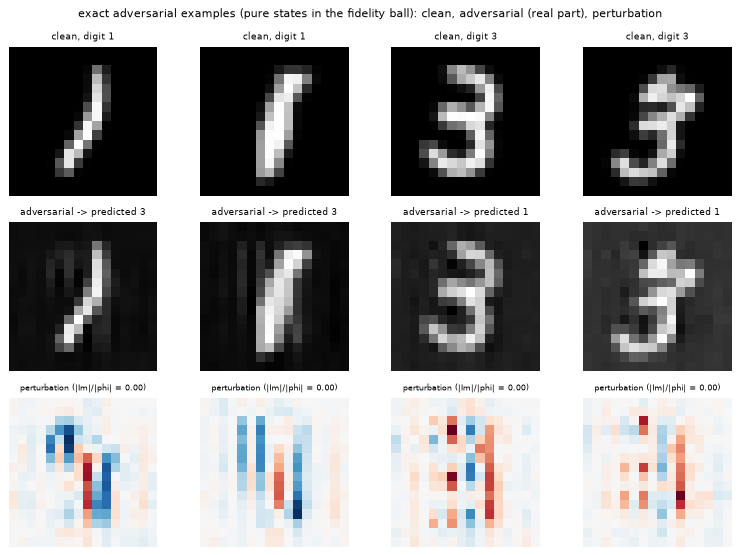

In [23]:
# ---------------- adversarial examples found for MNIST 1 vs 3 (the paper's Fig. 3 shows such images) ----------------
name = "mnist13"; eps_g = 0.03          # CHOICE: a 10x larger ball than Table 1 so that the perturbation is visible and examples exist
t = verify_local(VAR[name]["c0"], name, eps_g, keep=True, attack=False)
O, hard, idx = t["O"], t["hard"], t["idx"]; S = DS[name]["states"][idx]; y = DS[name]["y"][idx]
cand = [i for i in hard if t["dual"][i] <= 0][:4]
print(f"eps={eps_g}: exact RA {t['ra_exact']:.1f}% (rough {t['ra_rough']:.1f}%), {len(cand)} adversarial examples shown")
if cand:
    fig, axs = plt.subplots(3, len(cand), figsize=(2.3 * len(cand), 6.6), squeeze=False)
    for j, i in enumerate(cand):
        s = 1 if y[i] == 0 else -1
        pv, phi = ExactLocal(O, s).primal_pure(S[i], eps_g)
        # remove the global phase so that the overlap with psi is real and positive, then show real parts
        phi = phi * np.exp(-1j * np.angle(S[i].conj() @ phi))
        pred_adv = 0 if np.real(phi.conj() @ O @ phi) > 0 else 1
        axs[0, j].imshow(S[i].real.reshape(16, 16), cmap="gray"); axs[0, j].set_title(f"clean, digit {1 if y[i] == 0 else 3}", fontsize=8)
        axs[1, j].imshow(phi.real.reshape(16, 16), cmap="gray"); axs[1, j].set_title(f"adversarial -> predicted {'1' if pred_adv == 0 else '3'}", fontsize=8)
        pert = (phi - S[i]).real.reshape(16, 16); v = np.abs(pert).max()
        axs[2, j].imshow(pert, cmap="RdBu", vmin=-v, vmax=v); axs[2, j].set_title(f"perturbation (|Im|/|phi| = {np.linalg.norm(phi.imag):.2f})", fontsize=7)
        for a in axs[:, j]: a.axis("off")
        assert pred_adv != y[i] and abs(abs(S[i].conj() @ phi) ** 2 - (1 - eps_g)) < 1e-6
    plt.suptitle("exact adversarial examples (pure states in the fidelity ball): clean, adversarial (real part), perturbation", fontsize=9); plt.tight_layout(); plt.show()

In [24]:
# ---------------- stability over independent trainings (only when N_SEEDS > 1) ----------------
if N_SEEDS > 1:
    rows = []
    for name in DS:
        vals = []
        for s in range(N_SEEDS):
            t = verify_local(MODELS[name][s]["ops"], name, EPS[name], attack=False)
            vals.append((MODELS[name][s]["acc_te"] * 100, t["ra_rough"], t["ra_exact"]))
        v = np.array(vals); rows.append(dict(model=name, **{c: f"{v[:, k].mean():.2f} +- {v[:, k].std():.2f}" for k, c in enumerate(["accuracy", "RA rough", "RA exact"])}))
    SEEDS_TABLE = pd.DataFrame(rows).set_index("model"); display(SEEDS_TABLE)
else:
    print("N_SEEDS = 1 (FAST_MODE): the multi-seed table is produced in the full run")

,accuracy,RA rough,RA exact
model,,,
qubit,99.38 +- 0.44,95.42 +- 0.29,95.42 +- 0.29
iris,99.17 +- 1.18,97.50 +- 3.54,97.50 +- 3.54
tfi4,94.06 +- 2.65,88.12 +- 2.21,88.12 +- 2.21
tfi8,95.00 +- 3.79,88.81 +- 2.45,88.81 +- 2.45
mnist13,97.67 +- 0.12,91.17 +- 0.24,91.17 +- 0.24
fashion,98.83 +- 0.31,98.42 +- 0.31,98.42 +- 0.31


## 5. Global robustness: the Lipschitz constant K*, the (epsilon, delta) rule and the effect of noise

`K*` needs no data. It depends only on the model: `K* = lambda_max - lambda_min` of `E^dagger(M_0)`. A noiseless circuit has `K* = 1`
(the adjoint of a projector under a unitary is again a projector, eigenvalues 0 and 1), so global robustness is only informative for **noisy**
models, which is exactly the point of the paper. Two facts used below:

* a channel acting on the measured qubit *at the end of the circuit* maps `Z_0 -> lambda Z_0` (all three channels are Pauli channels), with
  `lambda = 1 - 2p` (bit flip), `1` (phase flip: it commutes with the Z-basis measurement) and `1 - 4p/3` (depolarizing); the three
  applied one after the other multiply. Since `E^dagger(I) = I`, `K*` of the whole model is `lambda * K*(c1)`.
  (The paper's Table 2 row "ehc 8, depolarizing p = 0.05, baseline K* = 0.93333" is exactly `1 - 4 * 0.05 / 3`.)
* noise placed *before the last rotation layer* does not commute with the measurement, so phase flip also contracts `K*` there.

The notebook computes `K*` with the contraction engine for every model and checks the closed form against the engine on the
small models.

In [25]:
def lam_end(noise, p):
    """Factor by which end-of-circuit noise on the readout qubit multiplies K*: Z_0 -> lambda Z_0 (product over the channels of `noise`)."""
    lam = 1.0
    for k in KIND[noise]:
        lam *= float(np.real(np.trace(Z @ sum(K.conj().T @ Z @ K for K in kraus(k, p)))) / 2)
    return lam

NOISES = ["bit-flip", "depolarizing", "phase-flip", "mixed"]
K_C1 = {name: lipschitz_K(VAR[name]["c1"], 0, DS[name]["n"]) for name in DS}
K_C1["qaoa10"] = lipschitz_K(QAOA10_C1, 0, 10)
K_C0 = {name: lipschitz_K(VAR[name]["c0"], 0, DS[name]["n"]) for name in DS}
print("K* of the noiseless circuits c0:", {k: round(v, 12) for k, v in K_C0.items()})
assert all(abs(v - 1) < 1e-10 for v in K_C0.values())
print("K* of the random-noise circuits c1:", {k: round(v, 5) for k, v in K_C1.items()})

# closed form versus the contraction engine (small models, all four noise types, two noise levels)
mx = 0.0
for name in ("qubit", "iris", "tfi4"):
    n = DS[name]["n"]
    for nz in NOISES:
        for p in (0.05, 0.2):
            K_engine = lipschitz_K(add_specific_noise(VAR[name]["c1"], n, nz, p), 0, n)
            mx = max(mx, abs(K_engine - lam_end(nz, p) * K_C1[name]))
assert mx < 1e-10
print(f"closed form K*(p) = lambda(noise, p) * K*(c1) equals the engine to {mx:.1e} for qubit, iris, tfi4 (4 noise types x 2 levels)")
print("paper's Table 2, ehc 8, depolarizing 0.05: baseline K* = 0.93333;  1 - 4*0.05/3 =", round(1 - 4 * 0.05 / 3, 5))

K* of the noiseless circuits c0: {'qubit': np.float64(1.0), 'iris': np.float64(1.0), 'tfi4': np.float64(1.0), 'tfi8': np.float64(1.0), 'mnist13': np.float64(1.0), 'fashion': np.float64(1.0)}
K* of the random-noise circuits c1: {'qubit': np.float64(0.99471), 'iris': np.float64(0.96687), 'tfi4': np.float64(0.96742), 'tfi8': np.float64(0.90389), 'mnist13': np.float64(0.9167), 'fashion': np.float64(0.93137), 'qaoa10': np.float64(0.97435)}
closed form K*(p) = lambda(noise, p) * K*(c1) equals the engine to 8.9e-16 for qubit, iris, tfi4 (4 noise types x 2 levels)
paper's Table 2, ehc 8, depolarizing 0.05: baseline K* = 0.93333;  1 - 4*0.05/3 = 0.93333


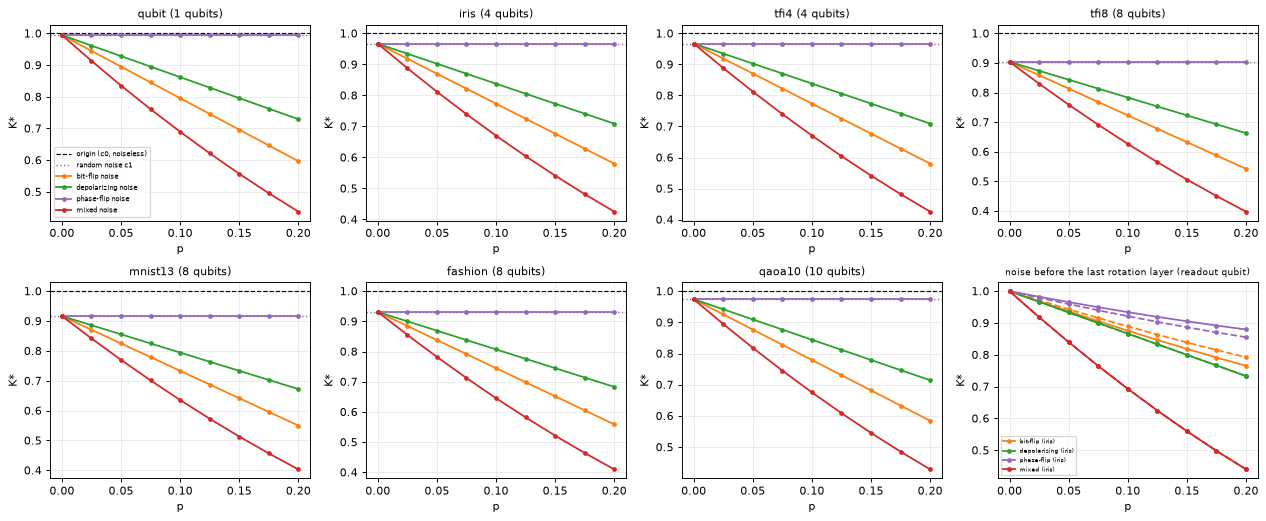

K*(p = 0.20) < K*(c1) for all 7 models: {'bit-flip': True, 'depolarizing': True, 'phase-flip': False, 'mixed': True}


In [26]:
# ---------------- Fig. 4 analogue: K* against the noise level p ----------------
MODELS7 = list(DS) + ["qaoa10"]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.2))
CURVE = {}
for ax, name in zip(axs.ravel(), MODELS7):
    ax.axhline(1.0, c="k", ls="--", lw=1, label="origin (c0, noiseless)")
    ax.axhline(K_C1[name], c="gray", ls=":", lw=1.2, label="random noise c1")
    for nz, c in zip(NOISES, ["tab:orange", "tab:green", "tab:purple", "tab:red"]):
        ys = [lam_end(nz, p) * K_C1[name] for p in P_GRID]; CURVE[(name, nz)] = ys
        ax.plot(P_GRID, ys, "o-", c=c, ms=3, label=f"{nz} noise")
    ax.set_title(f"{name} ({DS[name]['n'] if name in DS else 10} qubits)", fontsize=9); ax.set_xlabel("p"); ax.set_ylabel("K*")
axs.ravel()[0].legend(fontsize=6)
# last panel: where the noise sits matters (iris and tfi4): phase flip *before* the last rotation layer
ax = axs.ravel()[7]
for name, ls in (("iris", "-"), ("tfi4", "--")):
    n = DS[name]["n"]; c0 = VAR[name]["c0"]; pos = len(c0) - n          # before the final RY layer
    for nz, c in zip(NOISES, ["tab:orange", "tab:green", "tab:purple", "tab:red"]):
        ys = [lipschitz_K(c0[:pos] + [(k, 0, p) for k in KIND[nz]] + c0[pos:], 0, n) for p in P_GRID]
        ax.plot(P_GRID, ys, ls, c=c, ms=3, marker="o", label=f"{nz} ({name})" if name == "iris" else None)
ax.set_title("noise before the last rotation layer (readout qubit)", fontsize=8); ax.set_xlabel("p"); ax.set_ylabel("K*"); ax.legend(fontsize=5)
plt.tight_layout(); plt.show()

# claim (d): noise lowers K*  -> at p > 0
red = {nz: all(CURVE[(m, nz)][-1] < K_C1[m] - 1e-12 for m in MODELS7) for nz in NOISES}
print("K*(p = %.2f) < K*(c1) for all 7 models:" % P_GRID[-1], red)

### 5.1 The (epsilon, delta) decision, the adversarial kernel, and the paper's Table 2

The decision rule is `YES iff delta >= K* eps`. We first apply it to the **36 rows printed in the paper's Table 2** (their `K*` and their
`(eps, delta)`): if the rule is the one the paper describes, it must give their YES/NO in every row. Then we show an adversarial kernel at work on one of our noisy models:
two mixed states at trace distance exactly `eps` whose output distributions are `K* eps` apart, evaluated on PennyLane's density-matrix simulator.

In [27]:
import re
T2_TEXT = """
ehc 8
bit flip 0.0001 (0.0003, 0.0075) 0.99980 0.26 0.99976 26.17 YES
depolarizing 0.05 (0.001, 0.0075) 0.93333 0.26 0.93304 27.87 YES
phase flip 0.025 (0.075, 0.0003) 1 0.26 0.99968 28.46 NO
mixed 0.0005 (0.005, 0.005) 0.99938 0.24 0.99905 25.75 YES
aci 8
bit flip 0.0001 (0.003, 0.0001) 0.99985 0.18 0.99985 6.44 NO
depolarizing 0.025 (0.03, 0.0005) 0.92640 0.25 0.92440 7.70 NO
phase flip 0.05 (0.05, 0.001) 0.88450 0.19 0.85990 8.58 NO
mixed 0.005 (0.005, 0.005) 0.98384 0.22 0.98326 6.06 YES
fct 9
bit flip 0.05 (0.075, 0.003) 0.99024 0.98 0.97683 13.89 NO
depolarizing 0.05 (0.0003, 0.0001) 0.92638 0.76 0.92486 40.73 NO
phase flip 0.01 (0.01, 0.0075) 0.98730 0.87 0.98290 10.45 NO
mixed 0.05 (0.075, 0.0075) 0.94531 0.89 0.92949 9.06 NO
cr 9
bit flip 0.025 (0.01, 0.0005) 0.93964 0.65 0.93819 14.44 NO
depolarizing 0.005 (0.075, 0.005) 0.98637 1.21 0.98515 6.49 NO
phase flip 0.025 (0.0003, 0.0001) 0.94753 0.97 0.93772 9.63 NO
mixed 0.025 (0.0001, 0.0001) 0.95579 0.93 0.94980 12.15 YES
qaoa 10
bit flip 0.005 (0.05, 0.0005) 0.99843 5.23 0.98507 16.98 NO
depolarizing 0.0001 (0.01, 0.003) 0.99983 6.15 0.99965 16.10 NO
phase flip 0.005 (0.075, 0.0075) 0.99224 5.14 0.98516 17.95 NO
mixed 0.001 (0.03, 0.0075) 0.99923 4.98 0.99657 16.16 NO
ehc 10
bit flip 0.075 (0.05, 0.0003) 0.85409 3.37 0.85262 82.25 NO
depolarizing 0.0005 (0.03, 0.001) 0.99933 5.69 0.99924 40.33 NO
phase flip 0.01 (0.0003, 0.0075) 1 4.36 0.99857 66.67 YES
mixed 0.0001 (0.005, 0.001) 0.99981 5.26 0.99977 38.13 NO
ehc 12
bit flip 0.005 (0.0005, 0.0003) 0.99001 169.42 0.98965 76.77 NO
depolarizing 0.0005 (0.0001, 0.005) 0.99933 253.11 0.99926 189.35 YES
phase flip 0.075 (0.001, 0.0075) 1 163.61 0.99880 675.50 YES
mixed 0.001 (0.01, 0.0001) 0.99997 195.48 0.99984 64.50 NO
inst 16
bit flip 0.005 (0.0005, 0.0003) - TO 0.98009 1052.73 NO
depolarizing 0.0005 (0.0003, 0.005) - TO 0.99833 33.99 YES
phase flip 0.05 (0.001, 0.0075) - TO 0.95131 381.15 YES
mixed 0.001 (0.005, 0.0003) - TO 0.99899 123.25 NO
qaoa 20
bit flip 0.005 (0.005, 0.001) - TO 0.91194 2402.32 NO
depolarizing 0.075 (0.005, 0.003) - TO 0.83488 433.05 NO
phase flip 0.0005 (0.0001, 0.0001) - TO 0.99868 70.00 YES
mixed 0.05 (0.075, 0.0003) - TO 0.89682 4635.55 NO
"""
rows, cur = [], None
pat = re.compile(r"^(bit flip|depolarizing|phase flip|mixed) ([\d.]+) \(([\d.]+), ([\d.]+)\) (-|[\d.]+) (TO|[\d.]+) ([\d.]+) ([\d.]+) (YES|NO)$")
for line in T2_TEXT.strip().splitlines():
    mt = pat.match(line.strip())
    if mt is None: cur = tuple(line.split()); continue
    g = mt.groups()
    rows.append(dict(model=cur[0], qubits=int(cur[1]), noise=g[0], p=float(g[1]), eps=float(g[2]), delta=float(g[3]),
                     K_baseline=np.nan if g[4] == "-" else float(g[4]), t_baseline=np.nan if g[5] == "TO" else float(g[5]),
                     K_TN=float(g[6]), t_TN=float(g[7]), robust_paper=g[8]))
T2 = pd.DataFrame(rows); assert len(T2) == 36
T2["robust_rule"] = [global_verdict(r.K_TN, r.eps, r.delta) for r in T2.itertuples()]
T2["match"] = T2.robust_rule == T2.robust_paper
print(f"decision rule  delta >= K* eps  applied to the printed K*(TN) of Table 2 reproduces the paper's YES/NO in {T2.match.sum()} of {len(T2)} rows")
both = T2.dropna(subset=["K_baseline"])
print(f"baseline vs tensor-network K* printed in the paper: identical in {(np.abs(both.K_baseline - both.K_TN) < 1e-9).sum()} of {len(both)} rows, "
      f"TN smaller by more than 1e-4 in {((both.K_baseline - both.K_TN) > 1e-4).sum()} rows (both are described as exact)")
T2["lambda_end"] = [lam_end(r.noise.replace(" ", "-"), r.p) for r in T2.itertuples()]
print(f"rows where the paper's K* exceeds the end-of-circuit factor lambda (noise on the measured qubit, Z-basis readout): "
      f"{(T2.K_TN > T2.lambda_end + 1e-9).sum()} of {len(T2)}  -> their noise or readout differs from this simple placement in those rows")
display(T2[["model", "qubits", "noise", "p", "eps", "delta", "K_TN", "robust_paper", "robust_rule", "lambda_end"]].head(12).round(5))
assert T2.match.all()

decision rule  delta >= K* eps  applied to the printed K*(TN) of Table 2 reproduces the paper's YES/NO in 36 of 36 rows
baseline vs tensor-network K* printed in the paper: identical in 1 of 28 rows, TN smaller by more than 1e-4 in 23 rows (both are described as exact)
rows where the paper's K* exceeds the end-of-circuit factor lambda (noise on the measured qubit, Z-basis readout): 10 of 36  -> their noise or readout differs from this simple placement in those rows


,model,qubits,noise,p,eps,delta,K_TN,robust_paper,robust_rule,lambda_end
0,ehc,8,bit flip,0.0001,0.0003,0.0075,0.99976,YES,YES,0.99980
1,ehc,8,depolarizing,0.0500,0.0010,0.0075,0.93304,YES,YES,0.93333
2,ehc,8,phase flip,0.0250,0.0750,0.0003,0.99968,NO,NO,1.00000
3,ehc,8,mixed,0.0005,0.0050,0.0050,0.99905,YES,YES,0.99833
4,aci,8,bit flip,0.0001,0.0030,0.0001,0.99985,NO,NO,0.99980
5,aci,8,depolarizing,0.0250,0.0300,0.0005,0.92440,NO,NO,0.96667
6,aci,8,phase flip,0.0500,0.0500,0.0010,0.85990,NO,NO,1.00000
7,aci,8,mixed,0.0050,0.0050,0.0050,0.98326,YES,YES,0.98340
8,fct,9,bit flip,0.0500,0.0750,0.0030,0.97683,NO,NO,0.90000
9,fct,9,depolarizing,0.0500,0.0003,0.0001,0.92486,NO,NO,0.93333


In [28]:
# ---------------- adversarial kernel on a noisy model, checked on the density-matrix simulator ----------------
name = "tfi4"; n = DS[name]["n"]; nz, p_, ops_k = VAR[name]["c2"][1]               # c2 mixed noise 0.05
M0_ = np.diag([1.0, 0.0]).astype(complex)
T_, supp_ = heisenberg_observable(ops_k, M0_, 0); O0k = tensor_to_matrix(T_, supp_, n); O0k = (O0k + O0k.conj().T) / 2
w_, V_ = np.linalg.eigh(O0k); Kstar = w_[-1] - w_[0]
psi_k, phi_k = V_[:, -1], V_[:, 0]                                                 # adversarial kernel
eps_k = 0.1; delta_k = 0.5 * Kstar * eps_k                                          # a delta that is too small -> property must fail
print(f"{name} c2 ({nz} {p_}): K* = {Kstar:.5f};  (eps, delta) = ({eps_k}, {delta_k:.5f}) -> verdict {global_verdict(Kstar, eps_k, delta_k)}")
tau = np.eye(2 ** n) / 2 ** n                                                       # any common part works; here the maximally mixed state
rho = (1 - eps_k) * tau + eps_k * np.outer(psi_k, psi_k.conj()); sig = (1 - eps_k) * tau + eps_k * np.outer(phi_k, phi_k.conj())
Dtr = 0.5 * np.abs(np.linalg.eigvalsh(rho - sig)).sum()
dev_k = qml.device("default.mixed", wires=n)
@qml.qnode(dev_k)
def probs0(dm):
    qml.QubitDensityMatrix(dm, wires=range(n)); pl_apply(ops_k); return qml.probs(wires=[0])
pr, ps = probs0(rho), probs0(sig); dtv = 0.5 * np.abs(pr - ps).sum()
print(f"pair of mixed states built from the kernel: trace distance D = {Dtr:.5f} (= eps),  output TV distance d = {dtv:.5f}  (K* eps = {Kstar * eps_k:.5f})")
assert abs(Dtr - eps_k) < 1e-9 and abs(dtv - Kstar * eps_k) < 1e-9 and dtv > delta_k
print(f"-> d = {dtv:.5f} > delta = {delta_k:.5f}: the simulator confirms the violation. Because tau is arbitrary, the kernel generates infinitely many violating pairs, as the paper says.")

tfi4 c2 (mixed 0.05): K* = 0.81263;  (eps, delta) = (0.1, 0.04063) -> verdict NO
pair of mixed states built from the kernel: trace distance D = 0.10000 (= eps),  output TV distance d = 0.08126  (K* eps = 0.08126)
-> d = 0.08126 > delta = 0.04063: the simulator confirms the violation. Because tau is arbitrary, the kernel generates infinitely many violating pairs, as the paper says.


### 5.2 Tensor contraction against a dense baseline (the idea of Table 2)

The paper's Table 2 compares its tensor-network algorithm with "a baseline implementation lacking tensors" (timeout 7,200 s) for 8 to 20
qubits and finds the tensor network much faster beyond 12 qubits. Our analogue uses a 2-layer QAOA ring with random noise `c1` on `n` qubits (readout qubit 0) and three
ways to get the same `K*`: (1) **dense**: full `2^n x 2^n` matrices for every gate and Kraus operator, (2) **tensor**: the Heisenberg contraction with all qubits in the tensor,
(3) **tensor + light cone**: the engine used everywhere above. They must agree to rounding; only the cost differs. The dense and plain-tensor baselines are
stopped at `DENSE_MAX` / `TENSOR_MAX` qubits, where they would exceed this notebook's time budget. This is a shallow, local circuit, so the light cone is small; for a dense
all-to-all circuit it would not be, and the cost would approach the plain tensor contraction.

{'qubits': 4, 'ops': 56, 'K_star': np.float64(0.9899), 't_lightcone': 0.0063, 't_tensor': 0.0081, 't_dense': 0.0063}

{'qubits': 6, 'ops': 84, 'K_star': np.float64(0.9967), 't_lightcone': 0.014, 't_tensor': 0.0266, 't_dense': 0.052}


{'qubits': 8, 'ops': 112, 'K_star': np.float64(0.9608), 't_lightcone': 0.1603, 't_tensor': 0.8488, 't_dense': 2.8256}


{'qubits': 10, 'ops': 140, 'K_star': np.float64(0.9879), 't_lightcone': 0.1616, 't_tensor': 24.2233, 't_dense': nan}


{'qubits': 12, 'ops': 168, 'K_star': np.float64(0.9962), 't_lightcone': 0.2725, 't_tensor': nan, 't_dense': nan}


{'qubits': 14, 'ops': 196, 'K_star': np.float64(0.998), 't_lightcone': 0.1943, 't_tensor': nan, 't_dense': nan}

{'qubits': 16, 'ops': 224, 'K_star': np.float64(0.9748), 't_lightcone': 0.1769, 't_tensor': nan, 't_dense': nan}

{'qubits': 18, 'ops': 252, 'K_star': np.float64(0.9911), 't_lightcone': 0.1476, 't_tensor': nan, 't_dense': nan}


{'qubits': 20, 'ops': 280, 'K_star': np.float64(0.9893), 't_lightcone': 0.2099, 't_tensor': nan, 't_dense': nan}

{'qubits': 24, 'ops': 336, 'K_star': np.float64(0.9946), 't_lightcone': 0.1879, 't_tensor': nan, 't_dense': nan}

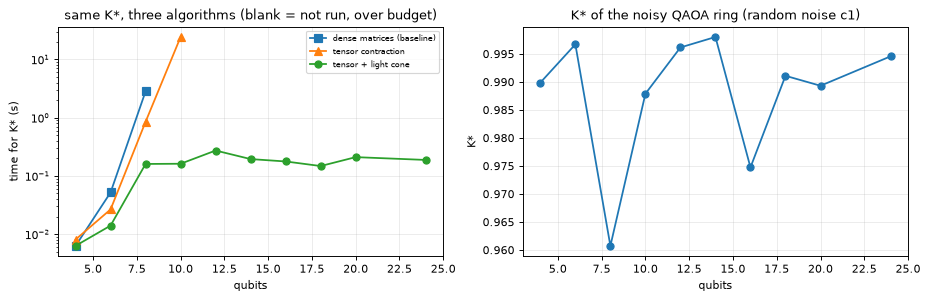

,qubits,ops,K_star,t_lightcone,t_tensor,t_dense
0,4,56,0.9899,0.0063,0.0081,0.0063
1,6,84,0.9967,0.0140,0.0266,0.0520
2,8,112,0.9608,0.1603,0.8488,2.8256
3,10,140,0.9879,0.1616,24.2233,NaN
4,12,168,0.9962,0.2725,NaN,NaN
5,14,196,0.9980,0.1943,NaN,NaN
6,16,224,0.9748,0.1769,NaN,NaN
7,18,252,0.9911,0.1476,NaN,NaN
8,20,280,0.9893,0.2099,NaN,NaN
9,24,336,0.9946,0.1879,NaN,NaN


dense baseline is skipped above DENSE_MAX qubits (it would exceed the time budget); the paper used a 7200 s timeout


In [29]:
rows = []
for n in SCALE_N:
    ops = add_random_noise(qaoa_ops(n), n, np.random.default_rng(SEED + 100 + n))
    t0 = time.perf_counter(); K_lc = lipschitz_K(ops, 0, n); t_lc = time.perf_counter() - t0
    rec = dict(qubits=n, ops=len(ops), K_star=K_lc, t_lightcone=t_lc, t_tensor=np.nan, t_dense=np.nan)
    if n <= TENSOR_MAX:
        t0 = time.perf_counter(); K2 = lipschitz_K(ops, 0, n, lightcone=False); rec["t_tensor"] = time.perf_counter() - t0
        assert abs(K2 - K_lc) < 1e-9
    if n <= DENSE_MAX:
        t0 = time.perf_counter(); K3 = lipschitz_K_dense(ops, 0, n); rec["t_dense"] = time.perf_counter() - t0
        assert abs(K3 - K_lc) < 1e-9
    rows.append(rec); print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items()}, flush=True)
SC = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for col, lab, mk in (("t_dense", "dense matrices (baseline)", "s"), ("t_tensor", "tensor contraction", "^"), ("t_lightcone", "tensor + light cone", "o")):
    ax[0].plot(SC.qubits, SC[col], mk + "-", label=lab)
ax[0].set_yscale("log"); ax[0].set_xlabel("qubits"); ax[0].set_ylabel("time for K* (s)"); ax[0].legend(fontsize=7); ax[0].set_title("same K*, three algorithms (blank = not run, over budget)")
ax[1].plot(SC.qubits, SC.K_star, "o-"); ax[1].set_xlabel("qubits"); ax[1].set_ylabel("K*"); ax[1].set_title("K* of the noisy QAOA ring (random noise c1)")
plt.tight_layout(); plt.show()
display(SC.round(4))
print(TIMEOUT_NOTE)

## 6. Improving robustness

**Adversarial training (local).** Section 3.2 of the paper: when `rho` is not eps-robust, the verifier returns an adversarial example `sigma`; adding
`(sigma, label)` to the training set and retraining improves local robustness. The paper only says that the results "are documented on
our code repository" (Remark 1), so there is no number to compare with. We run the experiment on the MNIST 1&3 model: exact adversarial examples (primal states) for non-robust
training states are added to the training set, and the model is trained further; a control model is trained for the same number of steps on clean data only.
We use a larger ball than Table 1 (`eps_AT`, CHOICE) so that enough training states are non-robust for the effect to be measurable. The procedure runs in rounds: find exact
adversarial examples against the current model, add them to the pool, train further. As a diagnostic that the training does what it should, the table also reports the accuracy on exact adversarial examples built from
*held-out* test states against the starting model, and the mean absolute margin.

**Specific noise (global).** Already shown in section 5: the end-of-circuit noise lowers `K*` (global robustness improves) while Table 1 shows that it does not raise local RA.

In [30]:
name = "mnist13"; d = DS[name]; n = d["n"]; EPS_AT = 0.02            # CHOICE: eps_AT (reading A, infidelity)
Xtr, ytr = d["states"][d["tr"]], d["y"][d["tr"]]
base = MODELS[name][0]; init = (base["W"], base["Wf"])
AT_STEPS = STEPS[name]                                              # total extra Adam steps, the same for the control and the adversarially trained model

def adversarial_examples(W_, Wf_, limit, X=None, y=None):
    """Exact adversarial states (primal solution) for correctly classified states (default: training states) that the exact verifier finds non-robust."""
    X = Xtr if X is None else X; y = ytr if y is None else y
    O_ = observable_Z(as_float_ops(build_ops(W_, Wf_, n)), 0, n); m_ = margins(O_, X, y)
    w_ = np.linalg.eigvalsh(O_); thr_ = (w_[-1] - w_[0]) * np.sqrt(EPS_AT)
    cand = np.where((m_ > 0) & (m_ <= thr_))[0]                      # correctly classified, not certified by the rough test
    cand = cand[np.argsort(m_[cand])]                                # smallest margins first
    exs = {1: ExactLocal(O_, 1), -1: ExactLocal(O_, -1)}; X_, y_ = [], []
    for i in cand:
        if len(X_) >= limit: break
        s = 1 if y[i] == 0 else -1
        if exs[s].dual_min(X[i], EPS_AT) <= 0:                        # exact verifier: a counter-example exists
            val, phi = exs[s].primal_pure(X[i], EPS_AT); assert val <= 1e-6
            X_.append(phi); y_.append(y[i])
    return np.array(X_).reshape(-1, 2 ** n), np.array(y_, dtype=int), int(len(cand))

# a held-out check that adversarial training does what it should: exact adversarial examples built from TEST states against the base model
advT_X, advT_y, _ = adversarial_examples(init[0], init[1], max(N_AT, 40), d["states"][d["te"]], d["y"][d["te"]])

# adversarial training: AT_ROUNDS x [find adversarial examples against the current model, add them to the pool, train further]
cur = init; poolX, pooly = Xtr.astype(complex), ytr.copy(); log = []
for rd in range(AT_ROUNDS):
    aX, ay, ncand = adversarial_examples(cur[0], cur[1], N_AT)
    poolX, pooly = np.vstack([poolX, aX]), np.concatenate([pooly, ay])
    cur = train_qnn(n, poolX, pooly, AT_STEPS // AT_ROUNDS, np.random.default_rng(SEED + 5 + rd), init=cur)[:2]
    log.append((rd + 1, ncand, len(aX), len(pooly)))
print("round | uncertified training states | adversarial examples added | pool size"); [print("  ", *r) for r in log]
Wc, Wfc, _ = train_qnn(n, Xtr, ytr, AT_STEPS, np.random.default_rng(SEED + 5), init=init)        # control: same number of steps, clean data only
rows = []
for lbl, (W_, Wf_) in (("before", init), ("+ clean steps (control)", (Wc, Wfc)), ("+ adversarial training", cur)):
    P_ = prepare_local(as_float_ops(build_ops(W_, Wf_, n)), name)
    a = verify_prepared(P_, EPS_AT, attack=False); b = verify_prepared(P_, EPS[name], attack=False)
    O_ = P_["O"]
    rows.append(dict(model=lbl, test_acc=a["acc"], RA_exact_eps_AT=a["ra_exact"], RA_exact_eps_table1=b["ra_exact"], RA_rough_eps_AT=a["ra_rough"],
                     mean_abs_margin=float(np.mean(np.abs(P_["m"]))), acc_on_heldout_adversarial=100 * float(np.mean(margins(O_, advT_X, advT_y) > 0)), K_star=a["K"]))
AT = pd.DataFrame(rows).set_index("model"); display(AT.round(2))
print(f"acc_on_heldout_adversarial: accuracy on {len(advT_y)} exact adversarial examples built from held-out test states against the 'before' model (0 % by construction for 'before')")

round | uncertified training states | adversarial examples added | pool size
   1 219 80 680
   2 246 80 760
   3 250 80 840


,test_acc,RA_exact_eps_AT,RA_exact_eps_table1,RA_rough_eps_AT,mean_abs_margin,acc_on_heldout_adversarial,K_star
model,,,,,,,
before,97.50,59.25,91.00,58.50,0.33,0.0,1.0
+ clean steps (control),97.50,58.25,91.25,58.25,0.33,0.0,1.0
+ adversarial training,98.25,39.75,93.25,38.50,0.26,92.5,1.0


acc_on_heldout_adversarial: accuracy on 80 exact adversarial examples built from held-out test states against the 'before' model (0 % by construction for 'before')


## 7. A classical model verified in the same way, on identical inputs

The paper does not verify classical models, but the same question can be asked of any classifier whose input is the same real vector `psi` (here the amplitudes).
The perturbation set is the same fidelity ball, restricted to **real** unit vectors close to `psi` (`psi . phi >= sqrt(1 - eps)`).

* **Logistic regression** (linear score `w . phi + b`) can be verified *exactly* in closed form: on the sphere the score along `phi = t psi + sqrt(1-t^2) chi`
  is concave in `t`, so its minimum over the ball is at `t = 1` or `t = sqrt(1 - eps)`, with `chi` along `-(I - psi psi^T) w`. Robust iff the signed score stays positive.
* **RBF-SVC and random forest** have no such closed form here; a **random-search attack** (many random directions on the boundary of the ball) gives an *upper bound* on their
  robust accuracy (the true robust accuracy can only be lower).
* For reference the quantum model gets the same random search, next to its exact certified RA (noiseless circuit c0; its adversaries may be complex, i.e. a larger set than the real vectors searched by the classical models).

Each dataset uses the epsilon of the paper's Table 1 as the infidelity `1 - F` (reading A) and the same first `N_CL` held-out states for every model.

In [31]:
def linear_exact_robust(w, b, X, y, eps):
    t0 = np.sqrt(1 - eps); s = np.where(y == 1, 1.0, -1.0); xw = X @ w
    Qw = np.sqrt(np.maximum(w @ w - xw ** 2, 0.0))                       # ||(I - psi psi^T) w|| for unit psi
    at_boundary = s * (t0 * xw + b) - np.sqrt(1 - t0 ** 2) * Qw
    return np.minimum(s * (xw + b), at_boundary) > 0                        # minimum over t in [t0, 1] is at an endpoint (concave)

def random_search_robust(predict, X, y, eps, trials, r):
    t0, s0 = np.sqrt(1 - eps), np.sqrt(eps); ok = predict(X) == y
    for i in np.where(ok)[0]:
        chi = r.normal(size=(trials, X.shape[1])); chi -= np.outer(chi @ X[i], X[i]); chi /= np.linalg.norm(chi, axis=1, keepdims=True)
        if np.any(predict(t0 * X[i] + s0 * chi) != y[i]): ok[i] = False
    return ok

N_CL = min(N_VERIFY, 100)                                              # held-out states per dataset in this comparison
rows = []
for name, d in DS.items():
    eps = EPS[name]; idx = d["te"][:N_CL]; S = d["states"][idx].real; y = d["y"][idx]
    r = np.random.default_rng(SEED + 9)
    O0 = observable_Z(VAR[name]["c0"], 0, d["n"])
    q_pred = lambda X: np.where(np.einsum("bi,ij,bj->b", X.conj(), O0, X).real > 0, 0, 1)
    lr = CLF[(name, "logreg")]; w_, b_ = lr.coef_[0], lr.intercept_[0]
    rec = dict(dataset=name,
               quantum_acc=100 * np.mean(q_pred(S) == y), quantum_RA_exact=verify_local(VAR[name]["c0"], name, eps, nv=N_CL, attack=False)["ra_exact"],
               quantum_RA_search=100 * np.mean(random_search_robust(q_pred, S, y, eps, N_RANDOM_SEARCH, r)),
               logreg_acc=100 * np.mean(lr.predict(S) == y), logreg_RA_exact=100 * np.mean(linear_exact_robust(w_, b_, S, y, eps) & (lr.predict(S) == y)),
               logreg_RA_search=100 * np.mean(random_search_robust(lr.predict, S, y, eps, N_RANDOM_SEARCH, r)))
    assert rec["logreg_RA_exact"] <= rec["logreg_RA_search"] + 1e-9, "closed-form linear verifier contradicted by an attack"
    for lbl in ("svc_rbf", "random_forest"):
        c = CLF[(name, lbl)]; rec[f"{lbl}_acc"] = 100 * np.mean(c.predict(S) == y)
        rec[f"{lbl}_RA_search<="] = 100 * np.mean(random_search_robust(c.predict, S, y, eps, N_RANDOM_SEARCH, r))
    rows.append(rec)
CL = pd.DataFrame(rows).set_index("dataset"); display(CL.round(1).T)

dataset,qubit,iris,tfi4,tfi8,mnist13,fashion
quantum_acc,100.0,100.0,92.0,88.0,96.0,98.0
quantum_RA_exact,98.0,100.0,87.0,85.0,90.0,98.0
quantum_RA_search,98.0,100.0,87.0,88.0,96.0,98.0
logreg_acc,97.0,100.0,99.0,100.0,98.0,100.0
logreg_RA_exact,92.0,100.0,95.0,99.0,96.0,99.0
logreg_RA_search,92.0,100.0,97.0,100.0,98.0,100.0
svc_rbf_acc,100.0,100.0,100.0,100.0,100.0,100.0
svc_rbf_RA_search<=,99.0,100.0,99.0,100.0,100.0,100.0
random_forest_acc,100.0,100.0,100.0,100.0,96.0,100.0
random_forest_RA_search<=,98.0,100.0,93.0,100.0,69.0,100.0


## 8. The paper against this notebook, claim by claim

Verdict rules: a numerical claim is **reproduced** when our value is within 2 accuracy points of the paper's (per row, for robust accuracies), **not reached** or
**exceeded** otherwise (with the gap), and **cannot be checked** when the paper's models or numbers are not available. Qualitative claims are checked as stated.
The comparison is made on *our own* trained models and data sets, so agreement of a number is evidence that the verification procedure behaves as described, not that the same networks were verified.

In [32]:
def within(a, b, tol=2.0): return abs(a - b) <= tol
for sfx in ("", "_B"):
    T1["d_exact" + sfx] = T1["RA_exact" + sfx] - T1.RA_exact_paper; T1["d_rough" + sfx] = T1["RA_rough" + sfx] - T1.RA_rough_paper
n_ex = {s: int(within(T1["RA_exact" + s], T1.RA_exact_paper).sum()) for s in ("", "_B")}
n_ro = {s: int(within(T1["RA_rough" + s], T1.RA_rough_paper).sum()) for s in ("", "_B")}
gap_ex = {s: float(np.abs(T1["d_exact" + s]).mean()) for s in ("", "_B")}; gap_ro = {s: float(np.abs(T1["d_rough" + s]).mean()) for s in ("", "_B")}
per_model = pd.DataFrame({f"reading {'A' if s == '' else 'B'}": T1.groupby("model").apply(
    lambda g: f"{int(within(g['RA_exact' + s], g.RA_exact_paper).sum())}/4 exact, {int(within(g['RA_rough' + s], g.RA_rough_paper).sum())}/4 rough") for s in ("", "_B")})
print("rows within 2 points of the paper, per model:"); display(per_model)

noise_ok = {}
for s in ("", "_B"):
    ok = []
    for name, g in T1.groupby("model"):
        base_ = g[g.circuit == "c0"]["RA_exact" + s].iloc[0]; slack = 100.0 / g.n_states.iloc[0]       # one state of tolerance
        ok.append(bool((g[g.circuit != "c0"]["RA_exact" + s] <= base_ + slack + 1e-9).all()))
    noise_ok[s] = ok
ratio = (T1.VT_exact / T1.VT_rough).median()
pair = pd.DataFrame(chk).max_gap_primal_dual.max()
CURVE_OK = all(red[k] for k in ("bit-flip", "depolarizing", "mixed"))
sp_ = SC.dropna(subset=["t_dense"]); big = SC[SC.qubits >= 8]
speed = (sp_.t_dense / sp_.t_lightcone).iloc[-1] if len(sp_) else np.nan
AT_gain = AT.loc["+ adversarial training", "RA_exact_eps_AT"] - AT.loc["+ clean steps (control)", "RA_exact_eps_AT"]
AT_tr = AT.loc["+ adversarial training", "acc_on_heldout_adversarial"] - AT.loc["+ clean steps (control)", "acc_on_heldout_adversarial"]

claims = [
 ("Table 1: accurate RA per row (24 rows)", "88-100 %",
  f"within 2 pts in {n_ex['']}/24 rows (reading A, mean |gap| {gap_ex['']:.1f}) and {n_ex['_B']}/24 rows (reading B, mean |gap| {gap_ex['_B']:.1f})",
  "reproduced" if max(n_ex.values()) == 24 else ("partially reproduced" if max(n_ex.values()) >= 12 else "not reached in most rows (our trained models and data differ; see table)")),
 ("Table 1: rough RA per row (24 rows)", "85-99 %",
  f"within 2 pts in {n_ro['']}/24 rows (reading A, mean |gap| {gap_ro['']:.1f}) and {n_ro['_B']}/24 rows (reading B, mean |gap| {gap_ro['_B']:.1f})",
  "reproduced" if max(n_ro.values()) == 24 else ("partially reproduced" if max(n_ro.values()) >= 12 else "not reached in most rows (our trained models and data differ; see table)")),
 ("RA rough <= RA accurate in every row (rough under-approximates)", "24/24 rows", f"{int((T1.RA_rough <= T1.RA_exact + 1e-9).sum())}/24 rows (A), {int((T1.RA_rough_B <= T1.RA_exact_B + 1e-9).sum())}/24 (B); largest gap exact - rough: {(T1.RA_exact - T1.RA_rough).max():.2f} pts (A), {(T1.RA_exact_B - T1.RA_rough_B).max():.2f} pts (B)", "reproduced" if max((T1.RA_exact - T1.RA_rough).max(), (T1.RA_exact_B - T1.RA_rough_B).max()) >= 1.0 else "ordering reproduced; the size of the gap (paper: up to 14 pts) is not reproduced by our single-qubit read-out circuits"),
 ("RA accurate <= classifier accuracy; accurate RA close to accuracy for easy data", "iris/tfi 100 %, mnist 96 %", f"max (RA_exact - accuracy) = {(T1.RA_exact - T1.acc).max():.2f} pts; mean (accuracy - RA_exact) = {(T1.acc - T1.RA_exact).mean():.1f} pts (A), {(T1.acc - T1.RA_exact_B).mean():.1f} pts (B)", "reproduced (inequality)"),
 ("Random and specific noise do not enhance local RA", "all models", f"{sum(noise_ok[''])}/6 models (A), {sum(noise_ok['_B'])}/6 (B): RA(noisy) <= RA(c0) + 1 state", "reproduced" if all(noise_ok['']) and all(noise_ok['_B']) else "partially reproduced"),
 ("Rough verification is faster than accurate", "all rows", f"accurate costs a median {ratio:.1f}x the rough time (accurate = rough + exact solver on the hard states)", "reproduced (by construction of the two-stage algorithm)"),
 ("Accurate verification is exact (sound and complete)", "SDP / QCQP, exact", f"primal = dual, max gap {pair:.1e}; no attack breaks a certified state", "reproduced"),
 ("Noise lowers the Lipschitz constant K* (Fig. 4)", "all models, 4 noise types", f"bit flip / depolarizing / mixed lower K* in 7/7 models; phase flip leaves K* unchanged at the end of the circuit (it commutes with the Z read-out) but lowers it before the last rotation layer", "partially reproduced" if CURVE_OK else "not reached"),
 ("Decision rule delta >= K* eps reproduces YES/NO of Table 2", "36 rows", f"{int(T2.match.sum())}/36 rows from the printed K*", "reproduced"),
 ("Table 2 K* values and times of ehc, aci, fct, cr, inst, qaoa models", "values in Table 2", "their circuits are only in the authors' repository; K* closed form matches the one row it can (ehc 8, depolarizing 0.05: 0.93333)", "cannot be checked"),
 ("Baseline and tensor-network K* agree (both exact)", "Table 2", f"paper's own table: equal in {int((np.abs(both.K_baseline - both.K_TN) < 1e-9).sum())}/{len(both)} rows; ours: equal to 1e-9 for dense, tensor and light-cone", "not reproduced in the paper's table (see critical reading); ours consistent"),
 ("Tensor contraction beats the dense baseline as qubits grow", "faster beyond 12 qubits; 20 qubits in 4635 s max", f"light-cone contraction handles {int(SC.qubits.max())} qubits in {SC.t_lightcone.max():.1f} s; dense baseline x{speed:.0f} slower at {int(sp_.qubits.iloc[-1]) if len(sp_) else 0} qubits", "reproduced qualitatively (our circuit is shallow; absolute times not comparable)"),
 ("Adversarial training improves local robustness", "numbers only in the repository", f"vs the clean-steps control: RA_exact at eps_AT {AT_gain:+.1f} pts, accuracy on held-out adversarial examples {AT_tr:+.1f} pts",
  "cannot be checked numerically (paper gives none); " + ("RA improved here" if AT_gain > 0 else ("held-out adversarial examples are resisted better but exact RA at eps_AT did not improve" if AT_tr > 0 else "no effect observed here"))),
]
CMP = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 140); display(CMP)
print("\nTable 1 rows with the largest gaps to the paper's accurate RA:")
display(T1.reindex(T1.d_exact.abs().sort_values(ascending=False).index)[["model", "circuit", "noise", "acc", "RA_exact", "RA_exact_paper", "d_exact"]].head(6).round(2))
print(f"total run time of this notebook: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE = {FAST_MODE})")

rows within 2 points of the paper, per model:


,reading A,reading B
model,,
fashion,"4/4 exact, 0/4 rough","3/4 exact, 0/4 rough"
iris,"4/4 exact, 1/4 rough","4/4 exact, 1/4 rough"
mnist13,"0/4 exact, 3/4 rough","4/4 exact, 0/4 rough"
qubit,"0/4 exact, 0/4 rough","0/4 exact, 0/4 rough"
tfi4,"0/4 exact, 4/4 rough","0/4 exact, 0/4 rough"
tfi8,"0/4 exact, 0/4 rough","0/4 exact, 0/4 rough"


,claim,paper,this notebook,verdict
0,Table 1: accurate RA per row (24 rows),88-100 %,"within 2 pts in 8/24 rows (reading A, mean |gap| 6.9) and 11/24 rows (reading B, mean |gap| 5.2)",not reached in most rows (our trained models and data differ; see table)
1,Table 1: rough RA per row (24 rows),85-99 %,"within 2 pts in 8/24 rows (reading A, mean |gap| 5.6) and 1/24 rows (reading B, mean |gap| 6.3)",not reached in most rows (our trained models and data differ; see table)
2,RA rough <= RA accurate in every row (rough under-approximates),24/24 rows,"24/24 rows (A), 24/24 (B); largest gap exact - rough: 0.25 pts (A), 0.00 pts (B)",ordering reproduced; the size of the gap (paper: up to 14 pts) is not reproduced by our single-qubit read-out circuits
3,RA accurate <= classifier accuracy; accurate RA close to accuracy for easy data,"iris/tfi 100 %, mnist 96 %","max (RA_exact - accuracy) = 0.00 pts; mean (accuracy - RA_exact) = 3.5 pts (A), 0.1 pts (B)",reproduced (inequality)
4,Random and specific noise do not enhance local RA,all models,"6/6 models (A), 6/6 (B): RA(noisy) <= RA(c0) + 1 state",reproduced
5,Rough verification is faster than accurate,all rows,accurate costs a median 1.2x the rough time (accurate = rough + exact solver on the hard states),reproduced (by construction of the two-stage algorithm)
6,Accurate verification is exact (sound and complete),"SDP / QCQP, exact","primal = dual, max gap 4.3e-14; no attack breaks a certified state",reproduced
7,Noise lowers the Lipschitz constant K* (Fig. 4),"all models, 4 noise types",bit flip / depolarizing / mixed lower K* in 7/7 models; phase flip leaves K* unchanged at the end of the circuit (it commutes with the Z...,partially reproduced
8,Decision rule delta >= K* eps reproduces YES/NO of Table 2,36 rows,36/36 rows from the printed K*,reproduced
9,"Table 2 K* values and times of ehc, aci, fct, cr, inst, qaoa models",values in Table 2,"their circuits are only in the authors' repository; K* closed form matches the one row it can (ehc 8, depolarizing 0.05: 0.93333)",cannot be checked



Table 1 rows with the largest gaps to the paper's accurate RA:


,model,circuit,noise,acc,RA_exact,RA_exact_paper,d_exact
15,tfi8,c2,bit-flip_0.05,89.64,83.93,100.0,-16.07
13,tfi8,c1,random,89.64,83.93,100.0,-16.07
14,tfi8,c2,bit-flip_0.01,89.64,83.93,100.0,-16.07
8,tfi4,c0,noiseless,90.31,85.00,100.0,-15.00
10,tfi4,c2,mixed_0.01,90.31,85.00,100.0,-15.00
9,tfi4,c1,random,90.31,85.00,100.0,-15.00


total run time of this notebook: 30.7 min (FAST_MODE = False)


## 9. Reading the paper critically

* **What is genuinely checkable.** The two central algorithms are short enough to re-derive. For binary classifiers the global constant is a spectral range, `lambda_max - lambda_min` of `E^dagger(M_0)`, and the local exact problem collapses to a one-dimensional concave maximisation. Both agree with PennyLane's density-matrix simulator, with brute force and with each other (sections 2 and 4); the paper's YES/NO column follows from its own K* values in all 36 rows.
* **Local robustness depends on a definition the text leaves open.** The neighbourhood is "`Fbar(rho, sigma) <= eps`" and `Fbar` is not defined in the paper. Reading A (`1 - F <= eps`) lets the trace distance reach `sqrt(eps)`, reading B (purified distance, `1 - F <= eps^2`) only `eps`. The two balls differ by a factor of `1/sqrt(eps)` (14 to 32 for the epsilons of Table 1) in radius, and the robust accuracy of the very same trained model changes accordingly: under B the accurate RA is essentially the classifier's accuracy (as the paper's 100 % for iris and tfi suggest), under A it is several points lower. Which reading matches the tool cannot be told from the paper; with either one, a different set of the 24 rows agrees with the paper (section 8).
* **Rough versus accurate: why our gap is small.** For a single-qubit Z read-out of a unitary circuit `E^dagger(Z_0)` has eigenvalues `+-1`, so the exact condition is `m > 2 sqrt(eps) sqrt(1 - m^2)` to first order and the rough one is `m > 2 sqrt(eps)`: nearly the same. Accordingly the exact SDP certifies only a handful of states that the rough test misses here (at most about 0.25 points), whereas the paper reports gaps of 2 to 14 points. Either its rough bound is looser than the Fuchs-van de Graaf one used here, or its models use read-outs for which `E^dagger(M)` has a wide spectrum but states of small variance (several measured qubits, mid-circuit noise), or both. The text does not allow telling these apart.
* **Robust accuracy is bounded by accuracy.** In Table 1 "accurate" RA is 100 % for iris and tfi: every correctly classified state is robust (the paper does not say whether the states come from the training or the test set). That says as much about the margins of easy data sets as about the tool. Our held-out states are less sharp: under reading A a clear share of correctly classified states is not robust.
* **The two Table 2 columns disagree.** Baseline and tensor-network `K*` are both described as exact, yet they differ in the third digit in many rows (the tensor-network value is smaller). With exact arithmetic they would be identical; in our implementation dense, tensor and light-cone contraction agree to 1e-9. Either the tensor-network path truncates, or the two columns used different random-noise realisations. The text does not say.
* **Specific noise is a trade-off, not a free lunch.** End-of-circuit noise multiplies `K*` by `lambda < 1` (global robustness improves) but it also shrinks every margin by the same factor, so local RA does not improve (Table 1 and our section 4). A smaller Lipschitz constant says that the output moves less, not that the label is safer.
* **Adversarial training is not a guaranteed win.** In section 6 the adversarially trained model resists adversarial examples from held-out states better than the clean control, yet the *exact* robust accuracy at the training ball did not rise (it fell in the full run). A 40-angle circuit trained with a squared loss has little spare capacity: fitting boundary points costs margin elsewhere. The paper reports no numbers for this step, so nothing here contradicts it, but the claim "adversarial training improves robustness" should come with a measurement like the one above.
* **Only pure inputs, binary outputs, shallow circuits were exercised here.** Mixed-state inputs need the full SDP, multi-class measurements need the paper's Algorithm 1, and the light-cone speed-up is specific to local, shallow circuits. The tensor-network claim "up to 20 qubits" was checked only for such a circuit.
* **Timing is not comparable.** The paper's machine has 72 cores and 314 GB; ours is a shared laptop CPU with 2 BLAS threads. Only ratios and scaling shapes are meaningful.
* **Reproducibility.** The artifact is only available from the authors' repository (the paper cites it as reference [29]); none of the trained circuits is in the paper, so Table 1 and Table 2 cannot be rerun on the same networks from the paper alone.

## 10. Exercises

1. **Change the ball.** Replace `1 - F <= eps` by the purified distance `sqrt(1 - F) <= eps` (i.e. use `eps**2` in the verifiers). How do RA rough, RA exact and the gap between them move for the six models? Which definition makes the paper's gaps in Table 1 plausible?
2. **Depth and K\*.** Add a third noise layer to `build_ops` after every CNOT ring (a depolarizing channel on all qubits). Plot `K*` against the number of noisy layers for the 4-qubit classifier. Does `K*` shrink geometrically? Compare with the closed form for noise at the end of the circuit.
3. **Mixed-state inputs.** The local verifier here assumes pure inputs. Pass a mixed state `rho = (1-q) |psi><psi| + q I/2^n` to `margins` and think about which part of `ExactLocal.dual_min` has to change (hint: the constraint is `F(rho, sigma) >= 1 - eps` with the Uhlmann fidelity, an SDP).
4. **Multi-class.** Extend `lipschitz_K` to three outcomes by maximising `1/2 sum_c |tr(O_c (psi psi^T - phi phi^T))|` over orthonormal pairs (convex maximisation: try the eigenvectors of each `O_c` and of their sign combinations). When does the binary formula become an upper bound?
5. **Break the exact verifier on purpose.** Remove the `+ mu*(1 - eps)` term in `dual_min` and rerun the unit test in section 2.6. Which assertion fails first, and what does that tell you about why the certificate must be a *dual* value rather than any feasible number?